In [ ]:
!pip install -q -U kaggle
!pip install -q transformers timm pycocotools torchmetrics ultralytics appdirs

In [ ]:
# libraries
import os, re, json, glob, time, random, shutil, zipfile, copy

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import subprocess

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.utils.flop_counter import FlopCounterMode

from transformers import DetrForObjectDetection, DetrImageProcessor
from ultralytics import YOLO
from torchvision.ops import batched_nms

from torchmetrics.detection import MeanAveragePrecision

from google.colab import userdata, drive
import traceback
from ultralytics.cfg import get_cfg
import pickle

import transformers, torchmetrics, ultralytics
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("ultralytics:", ultralytics.__version__)
print("torchmetrics:", torchmetrics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
transformers.logging.set_verbosity_error()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch: 2.14.1+cu130
transformers: 5.22.1
ultralytics: 8.4.215
torchmetrics: 1.9.0
GPU: Tesla T4


In [ ]:
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/cmpe_249_project_fog"
CKPT_DIR    = f"{PROJECT_DIR}/checkpoints"
RESULTS_DIR = f"{PROJECT_DIR}/results"
for d in (PROJECT_DIR, CKPT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

DATA_ROOT   = "/content/data"
FOGGY_DIR   = f"{DATA_ROOT}/foggy_cityscapes"
ANN_DIR     = f"{DATA_ROOT}/cityscapes"

SEED = 1

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

def make_generator(seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return g

set_seed()

assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU"
device = torch.device("cuda")

BETAS = [0.005, 0.01, 0.02]     # the three densities in Foggy Cityscapes
BETA_MAX = max(BETAS)           # used later to normalize beta to (0, 1]
NUM_CLASSES = 8

CFG = dict(
    seed=SEED,
    epochs=3,
    batch_size=4,
    num_workers=2,
    amp=True,
    film_lr=3e-4,
    backbone_lr=1e-5,
    head_lr=1e-4,
)
print("Config:", CFG)
print("Project dir:", PROJECT_DIR)

Mounted at /content/drive
Config: {'seed': 1, 'epochs': 3, 'batch_size': 4, 'num_workers': 2, 'amp': True, 'film_lr': 0.0003, 'backbone_lr': 1e-05, 'head_lr': 0.0001}
Project dir: /content/drive/MyDrive/cmpe_249_project_fog


**dataset**

In [ ]:
# ---------- settings ----------
USE_SCENES = "all"       # "all" = 2975 train + 500 val scenes | "refined" = 550-scene subset
DELETE_ZIP = True        # frees ~29 GB once images are extracted
MIN_BOX_PX = 4           # the dataset cell drops boxes with w<4 or h<4 (22 of 69,720)

#Id 8 = "cantsolve" is dropped.
CLASS_NAMES  = ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
CANTSOLVE_ID = 8
assert len(CLASS_NAMES) == NUM_CLASSES

RAW_DIR     = "/content/raw"
FOGGY_ZIP   = f"{RAW_DIR}/foggy-cityscapes.zip"
CS_ZIP      = f"{RAW_DIR}/gtBboxValidated_trainval.zip"
REFINED_TXT = f"{PROJECT_DIR}/foggy_trainval_refined_filenames.txt"
for d in (RAW_DIR, FOGGY_DIR, ANN_DIR):
    os.makedirs(d, exist_ok=True)

EXPECTED_IMAGES = {"all": 3 * (2975 + 500), "refined": 3 * 550}[USE_SCENES]

def list_foggy():
    return glob.glob(f"{FOGGY_DIR}/leftImg8bit_foggy/*/*/*.png")

# ---------- A) foggy images ----------
if len(list_foggy()) == EXPECTED_IMAGES:
    print("Foggy images already extracted.")
else:
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    if not os.path.exists(FOGGY_ZIP):
        !kaggle datasets download -d minhducnguyen9705/foggy-cityscapes -p {RAW_DIR}

    with zipfile.ZipFile(FOGGY_ZIP) as z:
        refined_text = z.read("foggy_trainval_refined_filenames.txt").decode()
        with open(REFINED_TXT, "w") as f:
            f.write(refined_text)
        refined = set(refined_text.splitlines())          # "split/city/scene"

        selected = []
        for n in z.namelist():
            parts = n.split("/")                          # leftImg8bit_foggy / split / city / file
            if len(parts) != 4 or not n.endswith(".png") or parts[0] != "leftImg8bit_foggy":
                continue
            _, split, city, fn = parts
            if split not in ("train", "val"):             # test labels are not public
                continue
            scene = fn.split("_leftImg8bit_foggy_")[0]
            if USE_SCENES == "refined" and f"{split}/{city}/{scene}" not in refined:
                continue
            selected.append(n)

        todo = [n for n in selected if not os.path.exists(f"{FOGGY_DIR}/{n}")]
        print(f"Selected {len(selected)} images, extracting {len(todo)}")
        for n in tqdm(todo, desc="Extracting"):
            z.extract(n, FOGGY_DIR)

    assert len(list_foggy()) == EXPECTED_IMAGES, "Image count mismatch after extraction"
    if DELETE_ZIP:
        os.remove(FOGGY_ZIP)

# ---------- B) box annotations ----------
if not glob.glob(f"{ANN_DIR}/gtBboxValidated/*/*/*_gtBboxValidated.json"):
    if not os.path.exists(CS_ZIP):
        if not os.path.isdir("/content/cityscapesScripts"):
            !git clone -q https://github.com/mcordts/cityscapesScripts.git /content/cityscapesScripts
        cs_user = userdata.get("CITYSCAPES_USER")
        answers = f"{cs_user}\n{userdata.get('CITYSCAPES_PASS')}\nN\n"
        r = subprocess.run(
            ["python", "/content/cityscapesScripts/cityscapesscripts/download/downloader.py",
             "-d", RAW_DIR, "gtBboxValidated_trainval.zip"],
            input=answers, text=True, capture_output=True)
        if not os.path.exists(CS_ZIP):
            print((r.stdout + r.stderr)[-600:].replace(cs_user, "***"))
            raise RuntimeError("Cityscapes download failed (see the scrubbed log above)")
    with zipfile.ZipFile(CS_ZIP) as z:
        z.extractall(ANN_DIR)

# ---------- C) index: one row per image, sorted so the order is identical on every run ----------
with open(REFINED_TXT) as f:
    refined_set = set(f.read().splitlines())

rows = []
for p in list_foggy():
    split, city, fn = p.split("/")[-3:]
    scene = fn.split("_leftImg8bit_foggy_")[0]
    rows.append(dict(
        split=split, city=city, scene=scene,
        beta=float(re.search(r"beta_(0\.\d+)", fn).group(1)),
        img_path=p,
        ann_path=f"{ANN_DIR}/gtBboxValidated/{split}/{city}/{scene}_gtBboxValidated.json",
        refined=f"{split}/{city}/{scene}" in refined_set,
    ))
index_df = (pd.DataFrame(rows)
            .sort_values(["split", "city", "scene", "beta"])
            .reset_index(drop=True))

# ---------- checks ----------
assert len(index_df) == EXPECTED_IMAGES
assert index_df.ann_path.map(os.path.exists).all(), "Some images have no annotation file"
assert sorted(index_df.beta.unique()) == BETAS
assert not (set(index_df[index_df.split == "train"].city) &
            set(index_df[index_df.split == "val"].city)), "Train/val share a city"
index_df.to_csv(f"{RESULTS_DIR}/data_index.csv", index=False)

print("\nImages per split x beta:")
print(index_df.groupby(["split", "beta"]).size().unstack())
print("\nScenes per split:", index_df.groupby("split").scene.nunique().to_dict())
print("Refined scenes per split:", index_df[index_df.refined].groupby("split").scene.nunique().to_dict())
print("Cities per split:", index_df.groupby("split").city.nunique().to_dict())
print(f"Disk free: {shutil.disk_usage('/content').free / 1e9:.0f} GB")

Dataset URL: https://www.kaggle.com/datasets/minhducnguyen9705/foggy-cityscapes
License(s): apache-2.0
100% 29.1G/29.1G [09:27<00:00, 55.0MB/s]

Selected 10425 images, extracting 10425


Extracting:   0%|          | 0/10425 [00:00<?, ?it/s]


Images per split x beta:
beta   0.005  0.010  0.020
split                     
train   2975   2975   2975
val      500    500    500

Scenes per split: {'train': 2975, 'val': 500}
Refined scenes per split: {'train': 498, 'val': 52}
Cities per split: {'train': 18, 'val': 3}
Disk free: 99 GB


In [ ]:
# colab space being used
!df -h /content | tail -1
!du -sh /content/data /content/raw /content/cityscapes* /root/.cache 2>/dev/null
print("Foggy zip still present:", os.path.exists(FOGGY_ZIP))   # should be False

overlay         113G   64G   50G  56% /
21G	/content/data
3.2M	/content/raw
12M	/content/cityscapesScripts
60M	/root/.cache
Foggy zip still present: False


In [ ]:
# hold out whole cities from train for checkpoint selection
# Roles: "train" = fit | "dev" = pick best epoch / tune | "test" = official Cityscapes val, final numbers only
train_df = index_df[index_df.split == "train"]
city_scenes = train_df.groupby("city").scene.nunique().sort_values(ascending=False)
print("Train cities (scenes per city):")
print(city_scenes.to_string())

N_HOLDOUT_CITIES = 3
HOLDOUT_CITIES = None
if HOLDOUT_CITIES is None:
    rng = random.Random(SEED)    # seeded, so the choice is identical on every run
    HOLDOUT_CITIES = sorted(rng.sample(sorted(city_scenes.index), N_HOLDOUT_CITIES))
print("\nHeld-out cities:", HOLDOUT_CITIES)

index_df["role"] = np.where(index_df.split == "val", "test",
                    np.where(index_df.city.isin(HOLDOUT_CITIES), "dev", "train"))

# ---- checks ----
cities_by_role = {r: set(g.city) for r, g in index_df.groupby("role")}
assert not (cities_by_role["train"] & cities_by_role["dev"])
assert not (cities_by_role["train"] & cities_by_role["test"])
assert not (cities_by_role["dev"] & cities_by_role["test"])
# all 3 betas of a scene must land in the same role
assert (index_df.groupby("scene").role.nunique() == 1).all()

print("\nImages per role x beta:")
print(index_df.groupby(["role", "beta"]).size().unstack())
print("\nScenes per role:", index_df.groupby("role").scene.nunique().to_dict())
index_df.to_csv(f"{RESULTS_DIR}/data_index.csv", index=False)

Train cities (scenes per city):
city
strasbourg         365
bremen             316
hamburg            248
dusseldorf         221
stuttgart          196
hanover            196
aachen             174
cologne            154
tubingen           144
weimar             142
zurich             122
jena               119
erfurt             109
krefeld             99
bochum              96
ulm                 95
monchengladbach     94
darmstadt           85

Held-out cities: ['bremen', 'darmstadt', 'hanover']

Images per role x beta:
beta   0.005  0.010  0.020
role                      
dev      597    597    597
test     500    500    500
train   2378   2378   2378

Scenes per role: {'dev': 597, 'test': 500, 'train': 2378}


Parsing boxes:   0%|          | 0/3475 [00:00<?, ?it/s]

Objects per class x role:
role        train   dev  test
person      14903  3208  3714
rider        1313   553   542
car         22533  6017  4135
truck         342   200    91
bus           304    78   101
train         131    49    23
motorcycle    586   122   150
bicycle      3697  1483  1888

Object size share per role (COCO thresholds, original pixels):
size   large  medium  small
role                       
dev    0.273   0.511  0.217
test   0.269   0.489  0.242
train  0.293   0.497  0.209

Scenes with zero valid boxes: {'dev': 0, 'test': 7, 'train': 10}


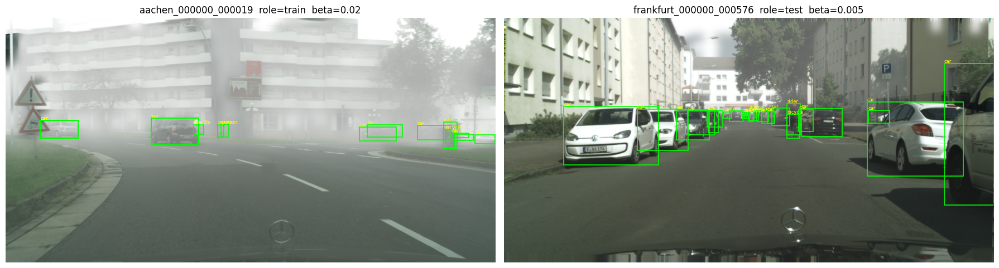

In [ ]:
# parse, filter and cache boxes
def load_boxes(ann_path):
    """Boxes as [x1, y1, x2, y2, class] in original 2048x1024 pixels. Drops cantsolve and tiny boxes."""
    with open(ann_path) as f:
        a = json.load(f)
    out = []
    for o in a["objects"]:
        c = int(np.argmax(o["soft_label"]))
        if c == CANTSOLVE_ID:
            continue
        x1, y1, x2, y2 = o["bbox"]
        if (x2 - x1) < MIN_BOX_PX or (y2 - y1) < MIN_BOX_PX:
            continue
        out.append([x1, y1, x2, y2, c])
    return np.array(out, dtype=np.float32).reshape(-1, 5)

# annotations are per scene, shared by the 3 betas, so parse each file once
BOXES = {p: load_boxes(p) for p in tqdm(index_df.ann_path.unique(), desc="Parsing boxes")}
index_df["n_boxes"] = index_df.ann_path.map(lambda p: len(BOXES[p]))

import pickle
with open(f"{RESULTS_DIR}/boxes.pkl", "wb") as f:
    pickle.dump(BOXES, f)

# ---- stats per role ----
scene_df = index_df.drop_duplicates("ann_path")
rows = []
for r in scene_df.itertuples():
    for x1, y1, x2, y2, c in BOXES[r.ann_path]:
        area = (x2 - x1) * (y2 - y1)
        rows.append((r.role, int(c), "small" if area < 32**2 else "medium" if area < 96**2 else "large"))
st = pd.DataFrame(rows, columns=["role", "cls", "size"])

print("Objects per class x role:")
t = st.groupby(["cls", "role"]).size().unstack(fill_value=0)
t.index = [CLASS_NAMES[i] for i in t.index]
print(t[["train", "dev", "test"]])
print("\nObject size share per role (COCO thresholds, original pixels):")
print(st.groupby("role")["size"].value_counts(normalize=True).unstack().round(3))
print("\nScenes with zero valid boxes:", scene_df.groupby("role").n_boxes.apply(lambda s: (s == 0).sum()).to_dict())

# ---- visual check: boxes on two foggy images ----
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, (role, beta) in zip(axes, [("train", 0.02), ("test", 0.005)]):
    row = index_df[(index_df.role == role) & (index_df.beta == beta) & (index_df.n_boxes >= 15)].iloc[0]
    ax.imshow(Image.open(row.img_path).convert("RGB"))
    for x1, y1, x2, y2, c in BOXES[row.ann_path]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1.2))
        ax.text(x1, y1 - 3, CLASS_NAMES[int(c)], color="yellow", fontsize=6)
    ax.set_title(f"{row.scene}  role={role}  beta={beta}"); ax.axis("off")
plt.tight_layout(); plt.show()

**detr preprocessing**

In [ ]:
n_empty_json = sum(len(json.load(open(p))["objects"]) == 0 for p in scene_df.ann_path)
print(f"Scenes whose JSON has no objects at all: {n_empty_json} | "
      f"scenes with no valid boxes after filtering: {int((scene_df.n_boxes == 0).sum())}")

# ---- beta normalization: log2 scale -> {0.005: 0, 0.01: 0.5, 0.02: 1} ----
def beta_to_norm(beta):
    return float(np.log2(beta / BETAS[0]) / np.log2(BETAS[-1] / BETAS[0]))
BETA_NORM = {b: beta_to_norm(b) for b in BETAS}
print("beta -> normalized:", BETA_NORM)

# ---- processor ----
DETR_SHORT_EDGE, DETR_LONG_EDGE = 800, 1333
processor = DetrImageProcessor.from_pretrained(
    "facebook/detr-resnet-50",
    size={"shortest_edge": DETR_SHORT_EDGE, "longest_edge": DETR_LONG_EDGE})

class DetrFogDataset(Dataset):
    def __init__(self, df, processor):
        self.records = df[["img_path", "ann_path", "beta"]].to_dict("records")
        self.processor = processor

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        image = Image.open(r["img_path"]).convert("RGB")
        anns = [{"bbox": [x1, y1, x2 - x1, y2 - y1], "category_id": int(c),
                 "area": float((x2 - x1) * (y2 - y1)), "iscrowd": 0}
                for x1, y1, x2, y2, c in BOXES[r["ann_path"]]]
        enc = self.processor(images=image,
                             annotations={"image_id": idx, "annotations": anns},
                             return_tensors="pt")
        return {"pixel_values": enc["pixel_values"][0],
                "pixel_mask": enc["pixel_mask"][0],
                "labels": enc["labels"][0],
                "beta": torch.tensor(r["beta"], dtype=torch.float32),
                "beta_norm": torch.tensor(BETA_NORM[r["beta"]], dtype=torch.float32)}

def detr_collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "pixel_mask":   torch.stack([b["pixel_mask"] for b in batch]),
            "labels":       [b["labels"] for b in batch],
            "beta":         torch.stack([b["beta"] for b in batch]),
            "beta_norm":    torch.stack([b["beta_norm"] for b in batch])}

def make_loader(role, shuffle, batch_size=None):
    ds = DetrFogDataset(index_df[index_df.role == role], processor)
    return DataLoader(ds, batch_size=batch_size or CFG["batch_size"], shuffle=shuffle,
                      collate_fn=detr_collate, num_workers=CFG["num_workers"],
                      worker_init_fn=seed_worker, generator=make_generator(), pin_memory=True)

train_loader = make_loader("train", shuffle=True)
dev_loader   = make_loader("dev",   shuffle=False)
test_loader  = make_loader("test",  shuffle=False)
print("Batches (train/dev/test):", len(train_loader), len(dev_loader), len(test_loader))

# ---- tests ----
ds = train_loader.dataset

# normalized cxcywh labels -> original-pixel xyxy must equal the cached boxes
i = next(k for k, r in enumerate(ds.records) if len(BOXES[r["ann_path"]]) > 5)
item = ds[i]
print("\npixel_values:", tuple(item["pixel_values"].shape), "| beta:", item["beta"].item(),
      "| beta_norm:", item["beta_norm"].item())
cx, cy, w, h = item["labels"]["boxes"].unbind(-1)
back = torch.stack([(cx - w/2) * 2048, (cy - h/2) * 1024, (cx + w/2) * 2048, (cy + h/2) * 1024], -1)
ref = torch.tensor(BOXES[ds.records[i]["ann_path"]])
assert back.shape == ref[:, :4].shape, "box count changed in the processor"
assert (item["labels"]["class_labels"] == ref[:, 4].long()).all(), "class labels changed"
print("Box round-trip max error (px):", (back - ref[:, :4]).abs().max().item())
assert (back - ref[:, :4]).abs().max() < 0.5

# a scene with no boxes must not crash the processor
j = next(k for k, r in enumerate(ds.records) if len(BOXES[r["ann_path"]]) == 0)
print("Empty-scene labels boxes shape:", tuple(ds[j]["labels"]["boxes"].shape))

# image loading speed (decides whether num_workers=2 starves the GPU)
t0 = time.time()
for k in range(10):
    _ = ds[k]
print(f"Mean time per item (load + resize + normalize): {(time.time() - t0) / 10 * 1000:.0f} ms")

Scenes whose JSON has no objects at all: 16 | scenes with no valid boxes after filtering: 17
beta -> normalized: {0.005: 0.0, 0.01: 0.5, 0.02: 1.0}


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

Batches (train/dev/test): 1784 448 375

pixel_values: (3, 666, 1333) | beta: 0.004999999888241291 | beta_norm: 0.0
Box round-trip max error (px): 0.0
Empty-scene labels boxes shape: (0, 4)
Mean time per item (load + resize + normalize): 99 ms


**evaluation metrics**

In [ ]:
SCALAR_KEYS = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large",
               "mar_1", "mar_10", "mar_100", "mar_small", "mar_medium", "mar_large"]

def labels_to_pixel_targets(label):
    """HF DETR label dict (normalized cxcywh) -> original-pixel xyxy target (verified: 0.0 px round-trip)."""
    h, w = label["orig_size"].tolist()
    cx, cy, bw, bh = label["boxes"].unbind(-1)
    boxes = torch.stack([(cx - bw/2) * w, (cy - bh/2) * h, (cx + bw/2) * w, (cy + bh/2) * h], -1)
    return {"boxes": boxes.float().cpu(), "labels": label["class_labels"].long().cpu()}

def _scalars(res):
    return {k: float(res[k]) for k in SCALAR_KEYS}

class DetectionEvaluator:
    """preds/targets: lists of dicts with xyxy boxes in ORIGINAL pixels (preds also scores, labels)."""
    def __init__(self):
        self.m_all = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
        self.m_beta = {b: MeanAveragePrecision(box_format="xyxy", iou_type="bbox") for b in BETAS}
        self.n_gt = np.zeros(NUM_CLASSES, dtype=int)

    def update(self, preds, targets, betas):
        self.m_all.update(preds, targets)
        for t in targets:
            self.n_gt += np.bincount(t["labels"].numpy(), minlength=NUM_CLASSES)
        for b in BETAS:
            sel = [i for i, x in enumerate(betas) if abs(x - b) < 1e-6]
            if sel:
                self.m_beta[b].update([preds[i] for i in sel], [targets[i] for i in sel])

    def compute(self):
        res = self.m_all.compute()
        per_class = pd.DataFrame({
            "class": [CLASS_NAMES[int(c)] for c in res["classes"]],
            "AP": res["map_per_class"].numpy(),
            "AR_100": res["mar_100_per_class"].numpy(),
        })
        per_class["n_gt"] = [self.n_gt[CLASS_NAMES.index(c)] for c in per_class["class"]]
        per_beta = pd.DataFrame({b: _scalars(m.compute()) for b, m in self.m_beta.items()
                                 if m._update_count > 0}).T
        per_beta.index.name = "beta"
        return {"overall": _scalars(res), "per_class": per_class, "per_beta": per_beta}

# self test
def eval_selftest(loader, n_batches=20):
    gts, betas = [], []
    for k, batch in enumerate(loader):
        if k == n_batches:
            break
        gts += [labels_to_pixel_targets(l) for l in batch["labels"]]
        betas += batch["beta"].tolist()

    def perfect(t):  return {"boxes": t["boxes"], "scores": torch.ones(len(t["boxes"])), "labels": t["labels"]}
    def shifted(t):  return {"boxes": t["boxes"] + torch.tensor([4., 0., 4., 0.]),
                             "scores": torch.ones(len(t["boxes"])), "labels": t["labels"]}
    def wrongcls(t): return {"boxes": t["boxes"], "scores": torch.ones(len(t["boxes"])),
                             "labels": (t["labels"] + 1) % NUM_CLASSES}
    def empty(t):    return {"boxes": torch.zeros(0, 4), "scores": torch.zeros(0), "labels": torch.zeros(0, dtype=torch.long)}

    rows = {}
    for name, fn in [("perfect", perfect), ("shifted 4px", shifted), ("wrong class", wrongcls), ("no predictions", empty)]:
        ev = DetectionEvaluator()
        ev.update([fn(t) for t in gts], gts, betas)
        rows[name] = ev.compute()["overall"]
    out = pd.DataFrame(rows).T[["map", "map_50", "map_75", "map_small", "map_medium", "map_large", "mar_100"]]
    print(f"Self-test on {len(gts)} images, no model involved:")
    print(out.round(3))
    assert out.loc["perfect", "map"] > 0.99
    assert out.loc["perfect", "map"] > out.loc["shifted 4px", "map"] > 0.02
    assert out.loc["shifted 4px", "map_50"] > out.loc["shifted 4px", "map_75"] - 1e-6
    assert out.loc["wrong class", "map"] < 0.01 and out.loc["no predictions", "map"] < 0.01
    print("Evaluator self-test passed.")

eval_selftest(test_loader)

Self-test on 80 images, no model involved:
                  map  map_50  map_75  map_small  map_medium  map_large  \
perfect         1.000    1.00   1.000      1.000       1.000      1.000   
shifted 4px     0.735    0.96   0.799      0.253       0.723      0.934   
wrong class     0.000    0.00   0.000      0.000       0.000      0.000   
no predictions  0.000    0.00   0.000      0.000       0.000      0.000   

                mar_100  
perfect           1.000  
shifted 4px       0.788  
wrong class       0.000  
no predictions    0.000  
Evaluator self-test passed.


In [ ]:
# DETR builder, optimizer groups, resumable training loop
def build_detr_baseline():
    set_seed()
    model = DetrForObjectDetection.from_pretrained(
        "facebook/detr-resnet-50", num_labels=NUM_CLASSES, ignore_mismatched_sizes=True)
    return model.to(device)

def make_optimizer(model):
    """Three learning-rate groups: FiLM (new, high LR) / backbone (low) / everything else (transformer + heads)."""
    groups = {"film": [], "backbone": [], "head": []}
    for n, p in model.named_parameters():
        if p.requires_grad:
            groups["film" if "film" in n else "backbone" if "backbone" in n else "head"].append(p)
    lrs = {"film": CFG["film_lr"], "backbone": CFG["backbone_lr"], "head": CFG["head_lr"]}
    pg = [{"params": v, "lr": lrs[k]} for k, v in groups.items() if v]
    for k, v in groups.items():
        if v:
            print(f"  {k:9s} lr={lrs[k]:.0e}  params={sum(p.numel() for p in v):,}")
    return AdamW(pg, weight_decay=1e-4)

def forward_loss(model, batch, use_beta):
    if use_beta:
        model.model.backbone.beta = batch["beta_norm"].to(device)
    labels = [{k: v.to(device) for k, v in t.items()} for t in batch["labels"]]
    with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
        out = model(pixel_values=batch["pixel_values"].to(device, non_blocking=True),
                    pixel_mask=batch["pixel_mask"].to(device, non_blocking=True),
                    labels=labels)
    return out.loss

def train_step(model, batch, optimizer, scaler, use_beta):
    loss = forward_loss(model, batch, use_beta)
    optimizer.zero_grad(set_to_none=True)
    if not torch.isfinite(loss):
        return None
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
    scaler.step(optimizer); scaler.update()
    return loss.item()

@torch.no_grad()
def dev_loss(model, loader, use_beta, max_steps=None):
    model.eval(); tot, n = 0.0, 0
    for i, batch in enumerate(tqdm(loader, desc="dev", leave=False)):
        if max_steps and i >= max_steps:
            break
        tot += forward_loss(model, batch, use_beta).item(); n += 1
    return tot / max(n, 1)

def fit(name, model, epochs, use_beta=False):
    """Resumable: re-running after a disconnect continues from the last finished epoch."""
    tr_loader, dv_loader = make_loader("train", True), make_loader("dev", False)
    optimizer = make_optimizer(model)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
    last, best = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_best.pt"
    state = dict(epoch=0, best_dev=float("inf"), history=[])
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"]); state = ck["state"]
        print(f"Resumed {name} after epoch {state['epoch']}")
    for epoch in range(state["epoch"], epochs):
        t0 = time.time(); model.train(); tot, n, skipped = 0.0, 0, 0
        for batch in tqdm(tr_loader, desc=f"{name} epoch {epoch+1}/{epochs}", leave=False):
            l = train_step(model, batch, optimizer, scaler, use_beta)
            if l is None: skipped += 1
            else: tot += l; n += 1
        dv = dev_loss(model, dv_loader, use_beta)
        state["epoch"] = epoch + 1
        state["history"].append(dict(epoch=epoch + 1, train_loss=tot / max(n, 1), dev_loss=dv,
                                     skipped_steps=skipped, minutes=(time.time() - t0) / 60))
        if dv < state["best_dev"]:
            state["best_dev"] = dv
            torch.save(model.state_dict(), best)
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scaler=scaler.state_dict(), state=state), last)
        print(state["history"][-1])
    pd.DataFrame(state["history"]).to_csv(f"{RESULTS_DIR}/{name}_history.csv", index=False)
    return state

**model**
- base
- detr + film (v1, v2, v3)

**base & eval**

In [ ]:
#DETR -> evaluator adapter
def decode_detr(logits, pred_boxes, label_dicts):
    """DETR outputs -> list of {boxes (xyxy, original px), scores, labels}, one per image."""
    probs = logits.float().softmax(-1)[..., :-1]          # drop the no-object class
    scores, labels = probs.max(-1)
    cx, cy, w, h = pred_boxes.float().unbind(-1)
    preds = []
    for i, lab in enumerate(label_dicts):
        H, W = lab["orig_size"].tolist()
        boxes = torch.stack([(cx[i] - w[i]/2) * W, (cy[i] - h[i]/2) * H,
                             (cx[i] + w[i]/2) * W, (cy[i] + h[i]/2) * H], -1)
        preds.append({"boxes": boxes.cpu(), "scores": scores[i].cpu(), "labels": labels[i].cpu()})
    return preds

@torch.no_grad()
def evaluate_detr(model, loader, use_beta, max_batches=None):
    model.eval()
    ev = DetectionEvaluator()
    for k, batch in enumerate(tqdm(loader, desc="evaluating", leave=False)):
        if max_batches and k == max_batches:
            break
        if use_beta:
            model.model.backbone.beta = batch["beta_norm"].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            out = model(pixel_values=batch["pixel_values"].to(device),
                        pixel_mask=batch["pixel_mask"].to(device))
        preds = decode_detr(out.logits, out.pred_boxes, batch["labels"])
        targets = [labels_to_pixel_targets(l) for l in batch["labels"]]
        ev.update(preds, targets, batch["beta"].tolist())
    return ev.compute()

# # ---- test 1: decode path with a synthetic "perfect" DETR (no model involved) ----
# batch = next(iter(test_loader))
# B, Q = len(batch["labels"]), 100
# logits = torch.full((B, Q, NUM_CLASSES + 1), -20.0); logits[..., -1] = 20.0      # everything = no-object
# boxes = torch.tensor([0.5, 0.5, 0.1, 0.1]).repeat(B, Q, 1)
# targets = []
# for i, lab in enumerate(batch["labels"]):
#     n = min(len(lab["class_labels"]), Q)                  # DETR has only 100 queries
#     logits[i, :n, -1] = -20.0
#     logits[i, torch.arange(n), lab["class_labels"][:n]] = 20.0
#     boxes[i, :n] = lab["boxes"][:n]
#     t = labels_to_pixel_targets(lab)
#     targets.append({"boxes": t["boxes"][:n], "labels": t["labels"][:n]})
# ev = DetectionEvaluator()
# ev.update(decode_detr(logits, boxes, batch["labels"]), targets, batch["beta"].tolist())
# print("Synthetic perfect DETR -> mAP:", round(ev.compute()["overall"]["map"], 4), "(must be ~1.0)")
# assert ev.compute()["overall"]["map"] > 0.99

# # ---- test 2: end to end on an UNTRAINED model: tables must populate, mAP must be ~0 ----
# untrained = build_detr_baseline()
# res = evaluate_detr(untrained, test_loader, use_beta=False, max_batches=6)
# print("\nUntrained DETR, 6 test batches (24 images): mAP", round(res["overall"]["map"], 4))
# print("\nper_beta:\n", res["per_beta"][["map", "map_50", "mar_100"]].round(4))
# print("\nper_class:\n", res["per_class"].round(4))
# del untrained; torch.cuda.empty_cache()

In [ ]:
#baseline training
assert CFG["epochs"] is not None, "Set epochs in the CFG cell (cell 3) first"
print(f"DETR baseline: {CFG['epochs']} epochs, batch {CFG['batch_size']}, "
      f"{DETR_SHORT_EDGE}/{DETR_LONG_EDGE}, seed {SEED}, AMP {CFG['amp']}")

detr_base = build_detr_baseline()
state = fit("detr_baseline", detr_base, epochs=CFG["epochs"], use_beta=False)

hist = pd.DataFrame(state["history"])
print(hist.round(4).to_string(index=False))
print(f"\nBest dev loss {state['best_dev']:.4f} at epoch {int(hist.loc[hist.dev_loss.idxmin(), 'epoch'])}")
print("Total skipped (non-finite) steps:", int(hist.skipped_steps.sum()))

plt.figure(figsize=(6, 3.5))
plt.plot(hist.epoch, hist.train_loss, marker="o", label="train")
plt.plot(hist.epoch, hist.dev_loss, marker="o", label="dev")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("DETR baseline"); plt.show()

DETR baseline: 5 epochs, batch 4, 800/1333, seed 1, AMP True


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


detr_baseline epoch 1/5:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.9165010737597674, 'dev_loss': 1.7744659845318114, 'skipped_steps': 0, 'minutes': 26.407280492782593}


... (4 outputs left out)

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.6432922305748068, 'dev_loss': 1.7149904077606541, 'skipped_steps': 0, 'minutes': 22.60959521532059}


detr_baseline epoch 4/5:   0%|          | 0/1784 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# test-set evaluation helpers + DETR baseline on the official val set
SWAP = {0.0: 1.0, 0.5: 0.0, 1.0: 0.5}        # every beta mapped to a WRONG beta (for the ablation)

def _beta_for_mode(b, mode):
    if mode == "true":
        return b
    if mode == "swapped":
        return torch.tensor([SWAP[round(float(x), 3)] for x in b], dtype=b.dtype)
    if mode == "constant":
        return torch.full_like(b, 0.5)
    raise ValueError(mode)

@torch.no_grad()
def evaluate_detr_mode(model, loader, beta_mode=None):
    """beta_mode=None for models without fog input; otherwise 'true' | 'swapped' | 'constant'."""
    model.eval()
    ev = DetectionEvaluator()
    for batch in tqdm(loader, desc=f"evaluating ({beta_mode})", leave=False):
        if beta_mode is not None:
            model.model.backbone.beta = _beta_for_mode(batch["beta_norm"], beta_mode).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            out = model(pixel_values=batch["pixel_values"].to(device),
                        pixel_mask=batch["pixel_mask"].to(device))
        preds = decode_detr(out.logits, out.pred_boxes, batch["labels"])
        targets = [labels_to_pixel_targets(l) for l in batch["labels"]]
        ev.update(preds, targets, batch["beta"].tolist())      # per-beta tables use the TRUE beta
    return ev.compute()

def save_results(name, res):
    with open(f"{RESULTS_DIR}/{name}_overall.json", "w") as f:
        json.dump(res["overall"], f, indent=1)
    res["per_class"].to_csv(f"{RESULTS_DIR}/{name}_per_class.csv", index=False)
    res["per_beta"].to_csv(f"{RESULTS_DIR}/{name}_per_beta.csv")

def load_results(name):
    with open(f"{RESULTS_DIR}/{name}_overall.json") as f:
        overall = json.load(f)
    return dict(overall=overall,
                per_class=pd.read_csv(f"{RESULTS_DIR}/{name}_per_class.csv"),
                per_beta=pd.read_csv(f"{RESULTS_DIR}/{name}_per_beta.csv", index_col=0))

# # ---- DETR baseline: best-dev-loss checkpoint, official val set ("test") ----
# # hist = pd.read_csv(f"{RESULTS_DIR}/detr_baseline_history.csv")
# # print("Baseline best epoch (by dev loss):", int(hist.loc[hist.dev_loss.idxmin(), "epoch"]), "of", len(hist))
# print("Baseline best epoch (by dev loss): 3 of 3")
# print("Best dev loss: 1.7150")

# detr_base = build_detr_baseline()
# detr_base.load_state_dict(torch.load(f"{CKPT_DIR}/detr_baseline_best.pt", map_location=device))
# res_base = evaluate_detr_mode(detr_base, test_loader, beta_mode=None)
# save_results("detr_baseline", res_base)

# print("\nOverall (test):")
# print(pd.Series(res_base["overall"]).round(4).to_string())
# print("\nPer beta:\n", res_base["per_beta"][["map", "map_50", "map_75", "mar_100"]].round(4))
# print("\nPer class:\n", res_base["per_class"].round(4))
# del detr_base; torch.cuda.empty_cache()

**detr + film & eval**

In [ ]:
# DETR + FiLM set up
class FogFiLM(nn.Module):
    """Normalized fog density -> per-channel (gamma, delta) for each ResNet stage."""
    def __init__(self, channels=(256, 512, 1024, 2048), emb=64):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(1, emb), nn.ReLU(), nn.Linear(emb, emb), nn.ReLU())
        self.heads = nn.ModuleList([nn.Linear(emb, 2 * c) for c in channels])
        for h in self.heads:                       # zero-init: gamma=1, delta=0 -> exact identity at start
            nn.init.zeros_(h.weight); nn.init.zeros_(h.bias)
        self.cond = None

    def set_beta(self, beta_norm):
        self.cond = self.embed(beta_norm.reshape(-1, 1).float())

    def apply_stage(self, k, x):
        gamma, delta = self.heads[k](self.cond).chunk(2, dim=1)
        gamma = gamma[:, :, None, None].to(x.dtype)
        delta = delta[:, :, None, None].to(x.dtype)
        return x * (1 + gamma) + delta

STAGE_CHANNELS = {1: 256, 2: 512, 3: 1024, 4: 2048}      # ResNet-50 layer1..layer4 outputs

def build_detr_film(stages=(1, 2, 3, 4)):
    model = build_detr_baseline()                         # same seed + same pretrained weights as the baseline
    backbone = model.model.backbone
    net = backbone.model                                  # the timm ResNet (has .layer1 ... .layer4)
    film = FogFiLM([STAGE_CHANNELS[s] for s in stages]).to(device)
    model.film = film                                     # registered: appears in state_dict, optimizer group "film"
    backbone.beta = None                                  # forward_loss()/evaluators set this before each forward

    def read_beta(module, args):
        if module.beta is None:
            raise RuntimeError("Set model.model.backbone.beta before the forward pass")
        film.set_beta(module.beta.to(device))
    backbone.register_forward_pre_hook(read_beta)

    # for k, s in enumerate(stages):
    #     layer = getattr(net, f"layer{s}", None)
    #     assert layer is not None, f"backbone has no layer{s}; print(net) to see the module names"
    #     layer.register_forward_hook(lambda m, i, o, k=k: film.apply_stage(k, o))
    for k, s in enumerate(stages):
      layer = getattr(net, f"layer{s}", None)
      assert layer is not None, f"backbone has no layer{s}"

      layer.register_forward_hook(
          lambda m, i, o, k=k: film.apply_stage(k, o),
          prepend=True,
        )
    return model

# # ---------------- tests ----------------
# batch = next(iter(dev_loader))
# px, pm = batch["pixel_values"].to(device), batch["pixel_mask"].to(device)
# B = px.shape[0]

# base_t = build_detr_baseline().eval()
# film_t = build_detr_film().eval()
# n_film = sum(p.numel() for p in film_t.film.parameters())
# n_all = sum(p.numel() for p in film_t.parameters())
# print(f"FiLM params: {n_film:,} ({n_film / (n_all - n_film):.2%} on top of DETR's {n_all - n_film:,})")

# with torch.no_grad():                                      # fp32, no autocast
#     film_t.model.backbone.beta = torch.zeros(B, device=device)
#     lb, lf = base_t(pixel_values=px, pixel_mask=pm).logits, film_t(pixel_values=px, pixel_mask=pm).logits
#     print("\nTest 1, FiLM == baseline at init, max |logit diff|:", (lb - lf).abs().max().item())
#     assert (lb - lf).abs().max().item() < 1e-3

#     for h in film_t.film.heads:                            # make FiLM non-trivial
#         nn.init.normal_(h.weight, std=0.02)
#     film_t.model.backbone.beta = torch.zeros(B, device=device)
#     l0 = film_t(pixel_values=px, pixel_mask=pm).logits
#     film_t.model.backbone.beta = torch.ones(B, device=device)
#     l1 = film_t(pixel_values=px, pixel_mask=pm).logits
#     print("Test 2, output changes with beta, max |logit diff|:", (l0 - l1).abs().max().item())
#     assert (l0 - l1).abs().max().item() > 1e-4, "beta is not reaching the network"
# # test 3
# film_t.zero_grad(set_to_none=True)
# film_t.model.backbone.beta = torch.full((B,), 0.5, device=device)

# out = film_t(pixel_values=px, pixel_mask=pm)
# loss = out.logits.float().square().mean()
# loss.backward()

# grad_sum = sum(
#     p.grad.abs().sum().item()
#     for p in film_t.film.parameters()
#     if p.grad is not None
# )

# print("FiLM gradient sum:", grad_sum)
# assert grad_sum > 0, "FiLM parameters are not receiving gradients"
# print("FiLM tests passed.")
# del base_t, film_t; torch.cuda.empty_cache()

DETR+FiLM: 3 epochs, batch 4, seed 1, film_lr 0.001


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

  film      lr=1e-03  params=503,488
  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


detr_film epoch 1/3:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 2.0607334662713277, 'dev_loss': 1.9010857615087713, 'skipped_steps': 0, 'minutes': 22.940911904970804}


... (2 outputs left out)

{'epoch': 2, 'train_loss': 1.7772495057684423, 'dev_loss': 1.7615025624898928, 'skipped_steps': 0, 'minutes': 22.92240702311198}


detr_film epoch 3/3:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.7111149655462916, 'dev_loss': 1.7415794768769826, 'skipped_steps': 0, 'minutes': 23.01014736096064}
 epoch  train_loss  dev_loss  skipped_steps  minutes
     1      2.0607    1.9011              0  22.9409
     2      1.7772    1.7615              0  22.9224
     3      1.7111    1.7416              0  23.0101

Best dev loss 1.7416 at epoch 3
Total skipped (non-finite) steps: 0


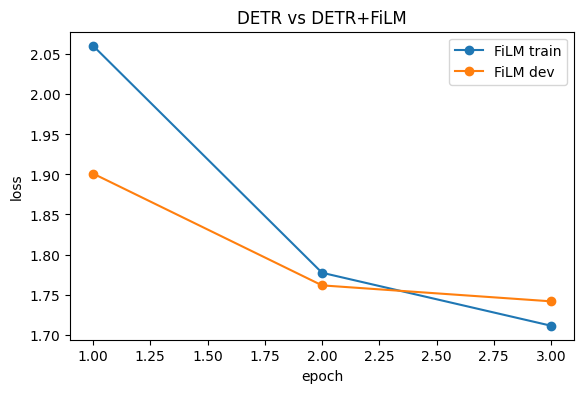

In [ ]:
# training DETR + FiLM
assert CFG["epochs"] is not None
print(f"DETR+FiLM: {CFG['epochs']} epochs, batch {CFG['batch_size']}, seed {SEED}, film_lr {CFG['film_lr']}")

detr_film = build_detr_film()
state = fit("detr_film", detr_film, epochs=CFG["epochs"], use_beta=True)

hist_f = pd.DataFrame(state["history"])
print(hist_f.round(4).to_string(index=False))
print(f"\nBest dev loss {state['best_dev']:.4f} at epoch {int(hist_f.loc[hist_f.dev_loss.idxmin(), 'epoch'])}")
print("Total skipped (non-finite) steps:", int(hist_f.skipped_steps.sum()))

plt.figure(figsize=(6.5, 4))
plt.plot(hist_f.epoch, hist_f.train_loss, "o-", label="FiLM train")
plt.plot(hist_f.epoch, hist_f.dev_loss, "o-", label="FiLM dev")
bp = f"{RESULTS_DIR}/detr_baseline_history.csv"
if os.path.exists(bp):
    hb = pd.read_csv(bp)
    plt.plot(hb.epoch, hb.train_loss, "o--", label="baseline train")
    plt.plot(hb.epoch, hb.dev_loss, "o--", label="baseline dev")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("DETR vs DETR+FiLM"); plt.show()

In [ ]:
# DETR+FiLM on the official val set, beta ablation, comparison vs baseline
detr_film = build_detr_film()
detr_film.load_state_dict(torch.load(f"{CKPT_DIR}/detr_film_best.pt", map_location=device))

res_film  = evaluate_detr_mode(detr_film, test_loader, "true");     save_results("detr_film", res_film)
res_swap  = evaluate_detr_mode(detr_film, test_loader, "swapped");  save_results("detr_film_swapped", res_swap)
res_const = evaluate_detr_mode(detr_film, test_loader, "constant"); save_results("detr_film_constant", res_const)
res_base  = load_results("detr_baseline")

keys = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large",
        "mar_1", "mar_10", "mar_100", "mar_small", "mar_medium", "mar_large"]
tbl = pd.DataFrame({"DETR": res_base["overall"], "DETR+FiLM": res_film["overall"],
                    "FiLM, swapped beta": res_swap["overall"], "FiLM, constant beta": res_const["overall"]}).loc[keys]
tbl["FiLM - DETR"] = tbl["DETR+FiLM"] - tbl["DETR"]
print("Overall (official val set):\n", tbl.round(4).to_string())

pb = pd.DataFrame({"DETR": res_base["per_beta"]["map"], "DETR+FiLM": res_film["per_beta"]["map"],
                   "FiLM, swapped": res_swap["per_beta"]["map"], "FiLM, constant": res_const["per_beta"]["map"]})
pb["FiLM - DETR"] = pb["DETR+FiLM"] - pb["DETR"]
print("\nmAP by true fog density (beta):\n", pb.round(4).to_string())

pc = res_base["per_class"][["class", "n_gt", "AP"]].rename(columns={"AP": "DETR"}).merge(
     res_film["per_class"][["class", "AP"]].rename(columns={"AP": "DETR+FiLM"}), on="class")
pc["FiLM - DETR"] = pc["DETR+FiLM"] - pc["DETR"]
print("\nPer-class AP:\n", pc.round(4).to_string(index=False))
del detr_film; torch.cuda.empty_cache()

In [ ]:
RESULTS_DIR = "/content/drive/MyDrive/cmpe_249_project_fog/results"

files_to_check = [
    "detr_baseline_overall.json",
    "detr_film_overall.json",
    "detr_baseline_per_beta.csv",
    "detr_film_per_beta.csv",
    "detr_baseline_per_class.csv",
    "detr_film_per_class.csv",
    "detr_film_swapped_overall.json",
]

for filename in files_to_check:
    path = os.path.join(RESULTS_DIR, filename)
    print(f"\n{'='*50}\n{filename}")

    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print("Missing or empty")
        continue

    try:
        if filename.endswith(".json"):
            with open(path) as f:
                print(json.dumps(json.load(f), indent=2))
        else:
            print(pd.read_csv(path).to_string(index=False))
    except Exception as e:
        print("Could not read:", e)


detr_baseline_overall.json
{
  "map": 0.1386841982603073,
  "map_50": 0.3040165305137634,
  "map_75": 0.11636090278625488,
  "map_small": 0.004915876779705286,
  "map_medium": 0.06661508977413177,
  "map_large": 0.28063493967056274,
  "mar_1": 0.11866079270839691,
  "mar_10": 0.20467737317085266,
  "mar_100": 0.22906535863876343,
  "mar_small": 0.01389714702963829,
  "mar_medium": 0.15580759942531586,
  "mar_large": 0.4197057783603668
}

detr_film_overall.json
{
  "map": 0.1122625470161438,
  "map_50": 0.2387063056230545,
  "map_75": 0.09613915532827377,
  "map_small": 0.003474451834335923,
  "map_medium": 0.05406123027205467,
  "map_large": 0.2346602976322174,
  "mar_1": 0.09983668476343155,
  "mar_10": 0.18782676756381989,
  "mar_100": 0.21654801070690155,
  "mar_small": 0.011874114163219929,
  "mar_medium": 0.1339709311723709,
  "mar_large": 0.40200939774513245
}

detr_baseline_per_beta.csv
 beta      map   map_50   map_75  map_small  map_medium  map_large    mar_1   mar_10  mar_10

**notes**

- Worse everywhere: mAP 0.139 → 0.112 (−2.6 points, about −19% relative). It’s worse at every beta (−0.030, −0.026, −0.024).
- Slower fit, not overfitting. FiLM’s train loss is higher at every epoch (2.06 vs 1.92 at epoch 1, 1.71 vs 1.64 at epoch 3). The dev-loss gap is largest at epoch 1 (0.13) and about 0.02 to 0.03 after. That fits “the module disturbed the pretrained network early and is partly recovering.” It’s a hypothesis I haven’t tested.
- The losses are in rarer classes: rider 0.129 → 0.067, truck 0.152 → 0.042, motorcycle 0.096 → 0.061, bicycle 0.103 → 0.080. Person, car and bus are flat or slightly up. Ignore train (69 objects). Rare classes usually suffer first in an under-trained DETR.
- FiLM’s mAP drops less from beta 0.005 to 0.02 (−6%) than the baseline’s (−9%). If the model ignores beta, that difference isn’t fog awareness, and it’s one seed with no confidence intervals.
- AP small is about 0.005 (baseline) and 0.003 (FiLM). Both models are essentially blind to small objects at this budget, so that column can’t separate them yet.

In [ ]:
# diagnostic
SWAP = {0.0: 1.0, 0.5: 0.0, 1.0: 0.5}
m = build_detr_film()
m.load_state_dict(torch.load(f"{CKPT_DIR}/detr_film_best.pt", map_location=device))
m.eval(); film = m.film

with torch.no_grad():
    # (1) what the FiLM module outputs for the three betas (fp32). Modulation is x*(1+g)+d
    film.set_beta(torch.tensor([0.0, 0.5, 1.0], device=device))
    emb = film.cond
    print(f"embedding: units exactly 0 for all 3 betas: {(emb.abs().sum(0) == 0).float().mean().item():.0%} | "
          f"mean spread across betas: {emb.std(0).mean().item():.4f}")
    for k, h in enumerate(film.heads):
        g, d = h(emb).chunk(2, dim=1)
        print(f"stage {k+1}: mean|g| {g.abs().mean():.4f}, g spread across betas {g.std(0).mean():.6f} | "
              f"mean|d| {d.abs().mean():.4f}, d spread across betas {d.std(0).mean():.6f}")

    # (2) full-model logits, true vs swapped beta, fp32 and fp16 (random image: tests whether beta CAN change the output)
    gen = torch.Generator().manual_seed(0)
    px = torch.randn(4, 3, 666, 1333, generator=gen).to(device)
    pm = torch.ones(4, 666, 1333, dtype=torch.long, device=device)
    true_b = torch.tensor([0.0, 0.5, 1.0, 0.5], device=device)
    swap_b = torch.tensor([SWAP[float(x)] for x in true_b.cpu()], device=device)
    for amp in (False, True):
        out = {}
        for name, b in (("true", true_b), ("swapped", swap_b)):
            m.model.backbone.beta = b
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                out[name] = m(pixel_values=px, pixel_mask=pm).logits.float()
        print(f"AMP={amp}: max |logit diff| true vs swapped = {(out['true'] - out['swapped']).abs().max().item():.6f}")

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

embedding: units exactly 0 for all 3 betas: 100% | mean spread across betas: 0.0000
stage 1: mean|g| 0.0481, g spread across betas 0.000000 | mean|d| 0.0242, d spread across betas 0.000000
stage 2: mean|g| 0.0483, g spread across betas 0.000000 | mean|d| 0.0171, d spread across betas 0.000000
stage 3: mean|g| 0.0465, g spread across betas 0.000000 | mean|d| 0.0210, d spread across betas 0.000000
stage 4: mean|g| 0.0484, g spread across betas 0.000000 | mean|d| 0.0174, d spread across betas 0.000000
AMP=False: max |logit diff| true vs swapped = 0.000000
AMP=True: max |logit diff| true vs swapped = 0.000000


**next attempt at film**

In [ ]:
# FiLM v2
class FogFiLMV2(nn.Module):
    def __init__(self, channels, emb=64):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(1, emb), nn.SiLU(), nn.Linear(emb, emb), nn.SiLU())
        self.heads = nn.ModuleList([nn.Linear(emb, 2 * c) for c in channels])
        for h in self.heads:                              # zero-init: exact identity at start
            nn.init.zeros_(h.weight); nn.init.zeros_(h.bias)
        self.cond = None

    def set_beta(self, beta_norm):
        with torch.autocast("cuda", enabled=False):
            self.cond = self.embed((2 * beta_norm.reshape(-1, 1).float() - 1))   # {0, .5, 1} -> {-1, 0, 1}

    def apply_stage(self, k, x):
        with torch.autocast("cuda", enabled=False):
            gamma, delta = self.heads[k](self.cond).chunk(2, dim=1)
            y = x.float() * (1 + gamma[:, :, None, None]) + delta[:, :, None, None]
        return y.to(x.dtype)

def build_detr_film_v2(stages=(3, 4), constant_beta=False):
    model = build_detr_baseline()
    backbone = model.model.backbone
    net = backbone.model
    film = FogFiLMV2([STAGE_CHANNELS[s] for s in stages]).to(device)
    model.film = film
    backbone.beta = None
    def read_beta(module, args):
        if module.beta is None:
            raise RuntimeError("Set model.model.backbone.beta before the forward pass")
        b = module.beta.to(device)
        film.set_beta(torch.full_like(b, 0.5) if constant_beta else b)   # control: identical code path, no fog info
    backbone.register_forward_pre_hook(read_beta)
    for k, s in enumerate(stages):
        getattr(net, f"layer{s}").register_forward_hook(lambda mod, i, o, k=k: film.apply_stage(k, o))
    return model

# test
px = torch.randn(2, 3, 666, 1333, device=device); pm = torch.ones(2, 666, 1333, dtype=torch.long, device=device)
base_t, v2 = build_detr_baseline().eval(), build_detr_film_v2().eval()
print("FiLM v2 params:", sum(p.numel() for p in v2.film.parameters()))
with torch.no_grad():
    v2.model.backbone.beta = torch.tensor([0.0, 1.0], device=device)
    d0 = (base_t(pixel_values=px, pixel_mask=pm).logits - v2(pixel_values=px, pixel_mask=pm).logits).abs().max().item()
    print("identity at init, max |logit diff| vs baseline:", d0); assert d0 < 1e-3
    for h in v2.film.heads: nn.init.normal_(h.weight, std=0.02)
    for amp in (False, True):
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            v2.model.backbone.beta = torch.zeros(2, device=device); a = v2(pixel_values=px, pixel_mask=pm).logits.float()
            v2.model.backbone.beta = torch.ones(2, device=device);  b = v2(pixel_values=px, pixel_mask=pm).logits.float()
        print(f"AMP={amp}: beta 0 vs 1, max |logit diff| = {(a - b).abs().max().item():.5f}")
del base_t, v2; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

FiLM v2 params: 403648
identity at init, max |logit diff| vs baseline: 0.0
AMP=False: beta 0 vs 1, max |logit diff| = 0.18660
AMP=True: beta 0 vs 1, max |logit diff| = 0.18616


In [ ]:
#FiLM v2, 1 epoch + beta-sensitivity check
CFG["film_lr"] = 3e-4          # was 1e-3 in the failed run (make_optimizer reads this at call time)
CFG["epochs"] = 3              # keep equal to baseline and v1 (also update cell 3 for consistency)

@torch.no_grad()
def beta_sensitivity(model):
    film = model.film
    film.set_beta(torch.tensor([0.0, 0.5, 1.0], device=device))
    out = {"embed_spread": film.cond.std(0).mean().item()}
    for k, h in enumerate(film.heads):
        g, d = h(film.cond).chunk(2, dim=1)
        out[f"s{k+1}_mean|g|"] = g.abs().mean().item()
        out[f"s{k+1}_g_spread"] = g.std(0).mean().item()
        out[f"s{k+1}_d_spread"] = d.std(0).mean().item()
    print({k: round(v, 6) for k, v in out.items()})
    return out

detr_film_v2 = build_detr_film_v2(stages=(3, 4))
state = fit("detr_film_v2", detr_film_v2, epochs=1, use_beta=True)
print("\nBeta sensitivity after epoch 1:")
beta_sensitivity(detr_film_v2)
print("\nReference epoch 1, baseline: train 1.9165 / dev 1.7745 | FiLM v1: train 2.0607 / dev 1.9011")

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

  film      lr=3e-04  params=403,648
  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


detr_film_v2 epoch 1/1:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.9809720748074922, 'dev_loss': 1.867278323641845, 'skipped_steps': 0, 'minutes': 23.32337408065796}

Beta sensitivity after epoch 1:
{'embed_spread': 0.017481, 's1_mean|g|': 0.009022, 's1_g_spread': 0.00377, 's1_d_spread': 0.003078, 's2_mean|g|': 0.009666, 's2_g_spread': 0.003839, 's2_d_spread': 0.002712}

Reference epoch 1, baseline: train 1.9165 / dev 1.7745 | FiLM v1: train 2.0607 / dev 1.9011


In [ ]:
#continue FiLM v2 to 3 epochs
state = fit("detr_film_v2", detr_film_v2, epochs=CFG["epochs"], use_beta=True)
print(pd.DataFrame(state["history"]).round(4).to_string(index=False))
print("\nBeta sensitivity after training:")
beta_sensitivity(detr_film_v2)

  film      lr=3e-04  params=403,648
  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525
Resumed detr_film_v2 after epoch 1


detr_film_v2 epoch 2/3:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.7603046638147712, 'dev_loss': 1.7982605349804675, 'skipped_steps': 0, 'minutes': 22.516830412546792}


detr_film_v2 epoch 3/3:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.7007779293263439, 'dev_loss': 1.743526469383921, 'skipped_steps': 0, 'minutes': 22.96970863342285}
 epoch  train_loss  dev_loss  skipped_steps  minutes
     1      1.9810    1.8673              0  23.3234
     2      1.7603    1.7983              0  22.5168
     3      1.7008    1.7435              0  22.9697

Beta sensitivity after training:
{'embed_spread': 0.014633, 's1_mean|g|': 0.014425, 's1_g_spread': 0.005037, 's1_d_spread': 0.004219, 's2_mean|g|': 0.015395, 's2_g_spread': 0.004871, 's2_d_spread': 0.00405}


{'embed_spread': 0.014632875099778175,
 's1_mean|g|': 0.014425034634768963,
 's1_g_spread': 0.0050367689691483974,
 's1_d_spread': 0.004219404421746731,
 's2_mean|g|': 0.01539490558207035,
 's2_g_spread': 0.004871074575930834,
 's2_d_spread': 0.004049685318022966}

**eval**

In [ ]:
# FiLM v2 on the official val set; true vs swapped beta
m = build_detr_film_v2(stages=(3, 4))
m.load_state_dict(torch.load(f"{CKPT_DIR}/detr_film_v2_best.pt", map_location=device))
res_true = evaluate_detr_mode(m, test_loader, "true");    save_results("detr_film_v2", res_true)
res_swap = evaluate_detr_mode(m, test_loader, "swapped"); save_results("detr_film_v2_swapped", res_swap)
res_base = load_results("detr_baseline")

keys = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large", "mar_100"]
tbl = pd.DataFrame({"DETR": res_base["overall"], "FiLM v2": res_true["overall"],
                    "FiLM v2, swapped beta": res_swap["overall"]}).loc[keys]
tbl["v2 - DETR"] = tbl["FiLM v2"] - tbl["DETR"]
tbl["true - swapped"] = tbl["FiLM v2"] - tbl["FiLM v2, swapped beta"]
print(tbl.round(4).to_string())
pb = pd.DataFrame({"DETR": res_base["per_beta"]["map"], "FiLM v2": res_true["per_beta"]["map"],
                   "FiLM v2, swapped": res_swap["per_beta"]["map"]})
print("\nmAP by true beta:\n", pb.round(4).to_string())

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

evaluating (true):   0%|          | 0/375 [00:00<?, ?it/s]

evaluating (swapped):   0%|          | 0/375 [00:00<?, ?it/s]

              DETR  FiLM v2  FiLM v2, swapped beta  v2 - DETR  true - swapped
map         0.1387   0.1278                 0.1261    -0.0109          0.0017
map_50      0.3040   0.2725                 0.2690    -0.0315          0.0035
map_75      0.1164   0.1097                 0.1059    -0.0067          0.0037
map_small   0.0049   0.0037                 0.0037    -0.0013          0.0000
map_medium  0.0666   0.0467                 0.0459    -0.0199          0.0008
map_large   0.2806   0.2665                 0.2649    -0.0141          0.0016
mar_100     0.2291   0.2309                 0.2295     0.0019          0.0014

mAP by true beta:
          DETR  FiLM v2  FiLM v2, swapped
beta                                    
0.005  0.1468   0.1276            0.1236
0.010  0.1436   0.1320            0.1294
0.020  0.1331   0.1292            0.1302


**next attempt at film (v3)**


In [ ]:
# FiLM v3 (post-backbone)
def build_detr_film_v3(constant_beta=False):
    model = build_detr_baseline()
    inner = model.model
    assert hasattr(inner, "input_projection"), \
        f"No input_projection; modules: {[n for n, _ in inner.named_children()]}"
    backbone = inner.backbone
    film = FogFiLMV2([256]).to(device)
    model.film = film
    backbone.beta = None
    def read_beta(module, args):
        if module.beta is None:
            raise RuntimeError("Set model.model.backbone.beta before the forward pass")
        b = module.beta.to(device)
        film.set_beta(torch.full_like(b, 0.5) if constant_beta else b)
    backbone.register_forward_pre_hook(read_beta)
    inner.input_projection.register_forward_hook(lambda m, i, o: film.apply_stage(0, o))
    return model

@torch.no_grad()
def beta_sensitivity(model):
    film = model.film
    film.set_beta(torch.tensor([0.0, 0.5, 1.0], device=device))
    out = {"embed_spread": film.cond.std(0).mean().item()}
    for k, h in enumerate(film.heads):
        g, d = h(film.cond).chunk(2, dim=1)
        out[f"s{k+1}_mean|g|"] = g.abs().mean().item()
        out[f"s{k+1}_g_spread"] = g.std(0).mean().item()
        out[f"s{k+1}_d_spread"] = d.std(0).mean().item()
    print({k: round(v, 6) for k, v in out.items()})

# smoke tests
px = torch.randn(2, 3, 666, 1333, device=device); pm = torch.ones(2, 666, 1333, dtype=torch.long, device=device)
base_t, v3 = build_detr_baseline().eval(), build_detr_film_v3().eval()
print("FiLM v3 params:", sum(p.numel() for p in v3.film.parameters()), "(I compute 37,568)")
with torch.no_grad():
    v3.model.backbone.beta = torch.tensor([0.0, 1.0], device=device)
    d0 = (base_t(pixel_values=px, pixel_mask=pm).logits - v3(pixel_values=px, pixel_mask=pm).logits).abs().max().item()
    print("identity at init, max |logit diff|:", d0); assert d0 < 1e-3
    for h in v3.film.heads: nn.init.normal_(h.weight, std=0.02)
    for amp in (False, True):
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            v3.model.backbone.beta = torch.zeros(2, device=device); a = v3(pixel_values=px, pixel_mask=pm).logits.float()
            v3.model.backbone.beta = torch.ones(2, device=device);  b = v3(pixel_values=px, pixel_mask=pm).logits.float()
        print(f"AMP={amp}: beta 0 vs 1, max |logit diff| = {(a - b).abs().max().item():.5f}")
del base_t, v3; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

FiLM v3 params: 37568 (I compute 37,568)
identity at init, max |logit diff|: 0.0
AMP=False: beta 0 vs 1, max |logit diff| = 0.06126
AMP=True: beta 0 vs 1, max |logit diff| = 0.06091


In [ ]:
# FiLM v3 training: 1 epoch + beta-sensitivity gate
CFG["film_lr"] = 3e-4
m3 = build_detr_film_v3()
state = fit("detr_film_v3", m3, epochs=1, use_beta=True)     # ~23 min; saves to Drive every epoch
print("\nBeta sensitivity after epoch 1:")
beta_sensitivity(m3)
print("\nReference after epoch 1 (dev loss): baseline 1.7745 | v1 1.9011 | v2 1.8673")

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

  film      lr=3e-04  params=37,568
  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


detr_film_v3 epoch 1/1:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.9640855904117294, 'dev_loss': 1.8979397811261671, 'skipped_steps': 0, 'minutes': 30.873679192860923}

Beta sensitivity after epoch 1:
{'embed_spread': 0.073918, 's1_mean|g|': 0.031198, 's1_g_spread': 0.039453, 's1_d_spread': 0.033038}

Reference after epoch 1 (dev loss): baseline 1.7745 | v1 1.9011 | v2 1.8673


**cancel, because worse than baseline already**

**yolo + film**

In [ ]:
# Ultralytics inspection (no training): what does the detection head receive?
import inspect
for name, loader in [("yolo11s.pt", YOLO)]:
    net = loader(name).model.to(device).eval()
    head = net.model[-1]
    seen = []
    hook = head.register_forward_pre_hook(lambda m, a: seen.append([tuple(t.shape) for t in a[0]]))
    with torch.no_grad():
        net(torch.zeros(1, 3, 640, 1280, device=device))
    hook.remove()
    print(f"\n{name}: {type(net).__name__} | head: {type(head).__name__} | head.f: {head.f}")
    print("  head.forward signature:", inspect.signature(head.forward))
    print("  params (M):", round(sum(p.numel() for p in net.parameters()) / 1e6, 2),
          "| has net.args:", hasattr(net, "args"))
    print("  feature maps entering the head:", seen[0] if seen else "pre-hook never fired")


yolo11s.pt: DetectionModel | head: Detect | head.f: [16, 19, 22]
  head.forward signature: (x: 'list[torch.Tensor]') -> 'dict[str, torch.Tensor] | torch.Tensor | tuple[torch.Tensor, dict[str, torch.Tensor]]'
  params (M): 9.46 | has net.args: True
  feature maps entering the head: [(1, 128, 80, 160), (1, 256, 40, 80), (1, 512, 20, 40)]


Batches (train/dev/test): 1784 448 375
image (3, 640, 1280) torch.uint8 | box round-trip max error (px): 0.0000
empty scene -> (0, 4)
{'img': (4, 3, 640, 1280), 'batch_idx': (66,), 'cls': (66, 1), 'bboxes': (66, 4), 'gt_groups': [31, 11, 12, 12], 'beta': (4,), 'beta_norm': (4,)}


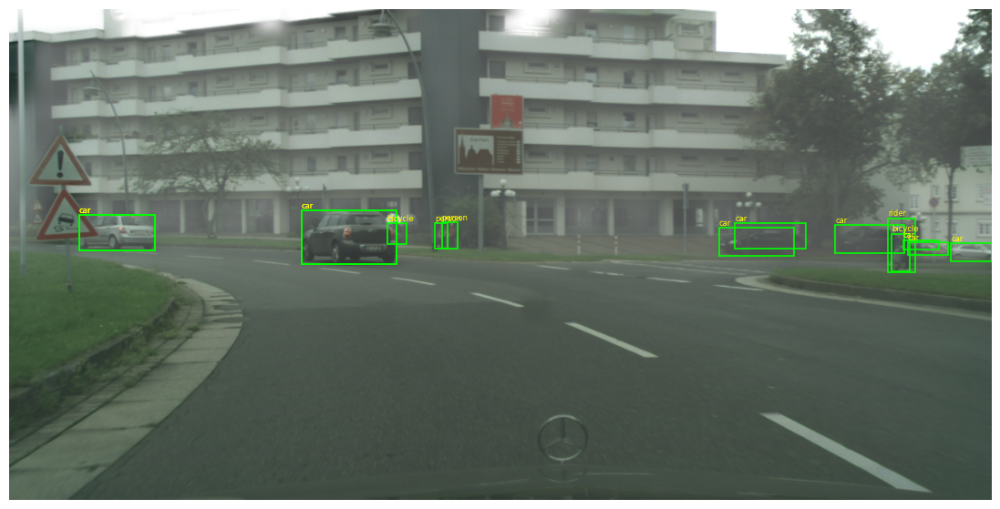

In [ ]:
# YOLO: same index, boxes, roles and beta as DETR
YOLO_W, YOLO_H = 1280, 640          # 2:1 like Cityscapes and divisible by 32, so no letterboxing

class YoloFogDataset(Dataset):
    def __init__(self, df):
        self.records = df[["img_path", "ann_path", "beta"]].to_dict("records")
    def __len__(self):
        return len(self.records)
    def __getitem__(self, idx):
        r = self.records[idx]
        img = Image.open(r["img_path"]).convert("RGB").resize((YOLO_W, YOLO_H), Image.BILINEAR)
        img = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)        # uint8, 3 x H x W
        bx = BOXES[r["ann_path"]]                                                # x1 y1 x2 y2 cls, original px
        if len(bx):
            xywh = np.stack([(bx[:, 0] + bx[:, 2]) / 2 / 2048, (bx[:, 1] + bx[:, 3]) / 2 / 1024,
                             (bx[:, 2] - bx[:, 0]) / 2048,     (bx[:, 3] - bx[:, 1]) / 1024], 1)
            bboxes, cls = torch.from_numpy(xywh).float(), torch.from_numpy(bx[:, 4]).long()
        else:
            bboxes, cls = torch.zeros(0, 4), torch.zeros(0, dtype=torch.long)
        return dict(img=img, bboxes=bboxes, cls=cls, beta=r["beta"], beta_norm=BETA_NORM[r["beta"]])

def yolo_collate(batch):
    n = [len(b["cls"]) for b in batch]
    return dict(
        img=torch.stack([b["img"] for b in batch]),                                 # uint8; scaled to 0-1 on the GPU
        batch_idx=torch.cat([torch.full((k,), i, dtype=torch.float32) for i, k in enumerate(n)]),
        cls=torch.cat([b["cls"] for b in batch]).float().view(-1, 1),
        bboxes=torch.cat([b["bboxes"] for b in batch]),
        gt_groups=n,
        beta=torch.tensor([b["beta"] for b in batch], dtype=torch.float32),
        beta_norm=torch.tensor([b["beta_norm"] for b in batch], dtype=torch.float32))

def make_yolo_loader(role, shuffle, batch_size=None):
    ds = YoloFogDataset(index_df[index_df.role == role])
    return DataLoader(ds, batch_size=batch_size or CFG["batch_size"], shuffle=shuffle, collate_fn=yolo_collate,
                      num_workers=CFG["num_workers"], worker_init_fn=seed_worker,
                      generator=make_generator(), pin_memory=True)

y_train, y_dev, y_test = make_yolo_loader("train", True), make_yolo_loader("dev", False), make_yolo_loader("test", False)
print("Batches (train/dev/test):", len(y_train), len(y_dev), len(y_test))

# ---- tests ----
ds = y_train.dataset
i = next(k for k, r in enumerate(ds.records) if len(BOXES[r["ann_path"]]) > 5)
it, ref = ds[i], torch.tensor(BOXES[ds.records[i]["ann_path"]])
cx, cy, w, h = it["bboxes"].unbind(-1)
back = torch.stack([(cx - w/2) * 2048, (cy - h/2) * 1024, (cx + w/2) * 2048, (cy + h/2) * 1024], -1)
err = (back - ref[:, :4]).abs().max().item()
print(f"image {tuple(it['img'].shape)} {it['img'].dtype} | box round-trip max error (px): {err:.4f}")
assert it["img"].shape == (3, YOLO_H, YOLO_W) and err < 0.5
assert (it["cls"] == ref[:, 4].long()).all()
j = next(k for k, r in enumerate(ds.records) if len(BOXES[r["ann_path"]]) == 0)
print("empty scene ->", tuple(ds[j]["bboxes"].shape))
b = next(iter(y_train))
print({k: (tuple(v.shape) if torch.is_tensor(v) else v) for k, v in b.items()})

fig, ax = plt.subplots(figsize=(14, 7)); ax.imshow(it["img"].permute(1, 2, 0).numpy())
for x, y, w_, h_, c in zip(cx * YOLO_W, cy * YOLO_H, w * YOLO_W, h * YOLO_H, it["cls"]):
    ax.add_patch(plt.Rectangle((x - w_/2, y - h_/2), w_, h_, fill=False, edgecolor="lime", linewidth=1.2))
    ax.text(x - w_/2, y - h_/2 - 3, CLASS_NAMES[int(c)], color="yellow", fontsize=6)
ax.axis("off"); plt.show()

In [ ]:
# YOLO11s: build with 8 classes, load pretrained weights
# lrs are guesses, not tuned
ULTRA = {"yolo11s": ("yolo11s.pt", YOLO, 8e-4, None)}

def build_ultra(key):
    wname, loader, _, cls_ = ULTRA[key]
    set_seed()
    pre = loader(wname).model
    net = (cls_ or type(pre))(copy.deepcopy(pre.yaml), ch=3, nc=NUM_CLASSES, verbose=False)
    net.load(pre)
    net.args = get_cfg()
    net.nc = NUM_CLASSES
    net.names = dict(enumerate(CLASS_NAMES))
    return net.to(device)

def to_ultra_batch(b):
    out = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in b.items()}
    out["img"] = out["img"].float() / 255
    return out

def fmt_items(items):
    if isinstance(items, dict):
        return {k: round(float(v.sum()) if torch.is_tensor(v) else float(v), 3) for k, v in items.items()}
    return [round(float(x), 3) for x in torch.as_tensor(items).flatten()]

In [ ]:
# YOLO decode -> evaluator adapter
SCALE_X, SCALE_Y = 2048 / YOLO_W, 1024 / YOLO_H

def decode_yolo(y, fmt="cxcywh", conf_thr=0.001, iou_thr=0.7, max_det=100, pre_nms=3000):
    """y: [B, 4+NC, A] raw eval output in 1280x640 px -> per-image dicts in ORIGINAL 2048x1024 px, xyxy."""
    out = []
    for yi in y.float():
        boxes, scores = yi[:4].T, yi[4:].T                          # [A,4], [A,NC]
        if fmt == "cxcywh":
            cx, cy, w, h = boxes.unbind(-1)
            boxes = torch.stack([cx - w/2, cy - h/2, cx + w/2, cy + h/2], -1)
        a_idx, c_idx = (scores > conf_thr).nonzero(as_tuple=True)   # multi-label: every (anchor, class) pair is a candidate
        s = scores[a_idx, c_idx]
        if len(s) > pre_nms:
            top = s.topk(pre_nms).indices
            a_idx, c_idx, s = a_idx[top], c_idx[top], s[top]
        b = boxes[a_idx]
        keep = batched_nms(b, s, c_idx, iou_thr)[:max_det]          # per-class NMS; 100 detections like DETR
        b = b[keep] * torch.tensor([SCALE_X, SCALE_Y, SCALE_X, SCALE_Y], device=b.device)
        out.append({"boxes": b.cpu(), "scores": s[keep].cpu(), "labels": c_idx[keep].cpu()})
    return out

def yolo_targets(batch):
    """YOLO batch (CPU tensors) -> original-pixel xyxy targets for the evaluator."""
    t, k = [], 0
    for n in batch["gt_groups"]:
        bb, cl = batch["bboxes"][k:k+n], batch["cls"][k:k+n].view(-1).long(); k += n
        cx, cy, w, h = bb.unbind(-1)
        t.append({"boxes": torch.stack([(cx - w/2) * 2048, (cy - h/2) * 1024,
                                        (cx + w/2) * 2048, (cy + h/2) * 1024], -1).float(), "labels": cl})
    return t

@torch.no_grad()
def evaluate_yolo(net, loader, max_batches=None, fmt="cxcywh"):
    net.eval(); ev = DetectionEvaluator()
    for k, batch in enumerate(tqdm(loader, desc="evaluating", leave=False)):
        if max_batches and k == max_batches:
            break
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            out = net(batch["img"].to(device).float() / 255)
        y = out[0] if isinstance(out, (tuple, list)) else out
        ev.update(decode_yolo(y, fmt), yolo_targets(batch), batch["beta"].tolist())
    return ev.compute()

# ---- test: a synthetic "perfect" YOLO output built from ground truth (no model) ----
b = next(iter(y_test)); B, A = len(b["gt_groups"]), 16800
y = torch.zeros(B, 4 + NUM_CLASSES, A); tg = yolo_targets(b); k = 0
for i, n in enumerate(b["gt_groups"]):
    n_ = min(n, 100)
    bb = b["bboxes"][k:k+n][:n_] * torch.tensor([YOLO_W, YOLO_H, YOLO_W, YOLO_H])   # -> cx,cy,w,h in 1280x640 px
    y[i, :4, :n_] = bb.T
    y[i, 4 + b["cls"][k:k+n][:n_].view(-1).long(), torch.arange(n_)] = 1.0
    tg[i] = {"boxes": tg[i]["boxes"][:n_], "labels": tg[i]["labels"][:n_]}; k += n
ev = DetectionEvaluator(); ev.update(decode_yolo(y), tg, b["beta"].tolist())
m = ev.compute()["overall"]["map"]
print("Synthetic perfect YOLO -> mAP:", round(m, 4), "(expect ~1.0)")
assert m > 0.95

Synthetic perfect YOLO -> mAP: 1.0 (expect ~1.0)


In [ ]:
# YOLO checks that need a model: (1) box format, (2) eval-mode loss, (3) speed and memory vs batch size
raw = next(iter(y_train)); fixed = to_ultra_batch(raw)
net = build_ultra("yolo11s"); net.train()
opt = AdamW(net.parameters(), lr=ULTRA["yolo11s"][2], weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
for step in range(150):
    with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
        loss, _ = net.loss(fixed)
    opt.zero_grad(set_to_none=True); scaler.scale(loss.sum()).backward()
    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
    scaler.step(opt); scaler.update()
print("overfit loss after 150 steps:", round(loss.sum().item(), 3))

net.eval()
with torch.no_grad():
    y = net(fixed["img"])[0]
    for fmt in ("cxcywh", "xyxy"):
        ev = DetectionEvaluator(); ev.update(decode_yolo(y, fmt), yolo_targets(raw), raw["beta"].tolist())
        r = ev.compute()["overall"]; print(f"format {fmt:7s}: mAP {r['map']:.3f} | mAP50 {r['map_50']:.3f}")
    top = y[0, 4:].max(0).values.topk(50).indices
    bx = y[0, :4, top]
    print("share of top-50 raw boxes with col2>col0 and col3>col1:", ((bx[2] > bx[0]) & (bx[3] > bx[1])).float().mean().item())
try:
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
        le, _ = net.loss(fixed)
    print("eval-mode loss runs:", round(le.sum().item(), 3), "(needed for dev loss)")
except Exception:
    traceback.print_exc(limit=-3)
del net, opt; torch.cuda.empty_cache()

def time_yolo(bs, n_warm=3, n_steps=12):
    try:
        net = build_ultra("yolo11s"); net.train()
        opt = AdamW(net.parameters(), lr=1e-4); scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
        it = iter(make_yolo_loader("train", True, batch_size=bs)); wait, comp = [], []
        torch.cuda.reset_peak_memory_stats()
        for i in range(n_warm + n_steps):
            t0 = time.time(); b = to_ultra_batch(next(it)); t1 = time.time()
            with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
                loss, _ = net.loss(b)
            opt.zero_grad(set_to_none=True); scaler.scale(loss.sum()).backward(); scaler.step(opt); scaler.update()
            torch.cuda.synchronize(); t2 = time.time()
            if i >= n_warm: wait.append(t1 - t0); comp.append(t2 - t1)
        step = np.mean(wait) + np.mean(comp)
        row = dict(batch=bs, wait_s=round(np.mean(wait), 2), compute_s=round(np.mean(comp), 2),
                   peak_GB=round(torch.cuda.max_memory_allocated() / 1e9, 1),
                   epoch_min=round((index_df.role == "train").sum() / bs * step / 60))
    except torch.cuda.OutOfMemoryError:
        row = dict(batch=bs, wait_s=None, compute_s=None, peak_GB="OOM", epoch_min=None)
    del net, opt; torch.cuda.empty_cache()
    return row
print(pd.DataFrame([time_yolo(bs) for bs in (4, 8, 16)]).to_string(index=False))

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
overfit loss after 150 steps: 3.847
format cxcywh : mAP 0.994 | mAP50 0.994
format xyxy   : mAP 0.000 | mAP50 0.000
share of top-50 raw boxes with col2>col0 and col3>col1: 0.0
eval-mode loss runs: 4.105 (needed for dev loss)
Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
 batch  wait_s  compute_s  peak_GB  epoch_min
     4    0.25       0.19      3.8         13
     8    0.50       0.29      5.6         12
    16    1.10       0.50      9.6         12


In [ ]:
# cache resized train+dev images as uint8 .npy (one-time), then verify against the PNGs and time the loader
CACHE_DIR = "/content/cache"; os.makedirs(CACHE_DIR, exist_ok=True)
def cache_path(role): return f"{CACHE_DIR}/yolo_{role}_{YOLO_W}x{YOLO_H}.npy"

need_gb = (index_df.role.isin(["train", "dev"]).sum()) * YOLO_H * YOLO_W * 3 / 1e9
free_gb = shutil.disk_usage("/content").free / 1e9
print(f"cache needs {need_gb:.1f} GB, disk free {free_gb:.0f} GB"); assert free_gb > need_gb + 10

def build_cache(role):
    p = cache_path(role); ds = YoloFogDataset(index_df[index_df.role == role])
    if os.path.exists(p):
        print(role, "cache already built"); return
    tmp = p + ".tmp"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(ds), YOLO_H, YOLO_W, 3))
    k = 0
    for b in tqdm(DataLoader(ds, batch_size=16, shuffle=False, collate_fn=yolo_collate,
                             num_workers=CFG["num_workers"]), desc=f"caching {role}"):
        n = len(b["img"]); mm[k:k+n] = b["img"].permute(0, 2, 3, 1).numpy(); k += n
    assert k == len(ds); mm.flush(); del mm; os.replace(tmp, p)

for role in ("dev", "train"): build_cache(role)

class YoloFogDatasetCached(YoloFogDataset):
    def __init__(self, df, path):
        super().__init__(df); self.path = path; self.mm = None
    def __getitem__(self, idx):
        if self.mm is None: self.mm = np.load(self.path, mmap_mode="r")
        r = self.records[idx]
        img = torch.from_numpy(np.ascontiguousarray(self.mm[idx])).permute(2, 0, 1)
        bx = BOXES[r["ann_path"]]
        if len(bx):
            xywh = np.stack([(bx[:, 0] + bx[:, 2]) / 2 / 2048, (bx[:, 1] + bx[:, 3]) / 2 / 1024,
                             (bx[:, 2] - bx[:, 0]) / 2048,     (bx[:, 3] - bx[:, 1]) / 1024], 1)
            bboxes, cls = torch.from_numpy(xywh).float(), torch.from_numpy(bx[:, 4]).long()
        else:
            bboxes, cls = torch.zeros(0, 4), torch.zeros(0, dtype=torch.long)
        return dict(img=img, bboxes=bboxes, cls=cls, beta=r["beta"], beta_norm=BETA_NORM[r["beta"]])

def make_yolo_loader_c(role, shuffle, batch_size):
    df = index_df[index_df.role == role]
    ds = YoloFogDatasetCached(df, cache_path(role)) if role in ("train", "dev") else YoloFogDataset(df)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=yolo_collate,
                      num_workers=CFG["num_workers"], worker_init_fn=seed_worker,
                      generator=make_generator(), pin_memory=True)

# ---- verify: cached pixels must equal freshly decoded PNGs ----
dsC = YoloFogDatasetCached(index_df[index_df.role == "train"], cache_path("train"))
dsP = YoloFogDataset(index_df[index_df.role == "train"])
for i in (0, 1234, len(dsC) - 1):
    assert torch.equal(dsC[i]["img"], dsP[i]["img"]), f"cache mismatch at {i}"
print("cache matches the PNGs (3 spot checks)")

# ---- loader speed with the cache (compute is ~27-35 img/s; the loader should be well above that) ----
it = iter(make_yolo_loader_c("train", True, 8)); next(it); t0 = time.time()
for _ in range(40): next(it)
rate = 40 * 8 / (time.time() - t0)
print(f"cached loader: {rate:.0f} img/s -> loading alone would take {(index_df.role == 'train').sum() / rate / 60:.1f} min/epoch")

cache needs 21.9 GB, disk free 99 GB


caching dev:   0%|          | 0/112 [00:00<?, ?it/s]

caching train:   0%|          | 0/446 [00:00<?, ?it/s]

/tmp/ipykernel_2009/518660449.py:29: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  img = torch.from_numpy(np.ascontiguousarray(self.mm[idx])).permute(2, 0, 1)


cache matches the PNGs (3 spot checks)
cached loader: 74 img/s -> loading alone would take 1.6 min/epoch


**baseline yolo**

In [ ]:
YOLO_BS, YOLO_EPOCHS, YOLO_LR, YOLO_WARMUP = 8, 10, 8e-4, 300   # lr = Ultralytics' AdamW auto-rule for nc=8

def yolo_loss(net, raw, use_beta=False):
    b = to_ultra_batch(raw)
    if use_beta: net.beta = raw["beta_norm"].to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
        loss, _ = net.loss(b)
    return loss.sum(), len(raw["gt_groups"])

@torch.no_grad()
def yolo_dev_loss(net, loader, use_beta=False):
    net.eval(); tot, n = 0.0, 0
    for raw in tqdm(loader, desc="dev", leave=False):
        l, bs = yolo_loss(net, raw, use_beta); tot += l.item(); n += bs
    return tot / n

def fit_yolo(name, build, epochs, use_beta=False):
    net = build()
    opt = AdamW(net.parameters(), lr=YOLO_LR, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
    tr, dv = make_yolo_loader_c("train", True, YOLO_BS), make_yolo_loader_c("dev", False, YOLO_BS)
    last, best = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_best.pt"
    state = dict(epoch=0, step=0, best_dev=float("inf"), history=[])
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        net.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"]); state = ck["state"]
        print(f"Resumed {name} after epoch {state['epoch']}")
    for epoch in range(state["epoch"], epochs):
        t0 = time.time(); net.train(); tot, n, skipped = 0.0, 0, 0
        for raw in tqdm(tr, desc=f"{name} epoch {epoch+1}/{epochs}", leave=False):
            for g in opt.param_groups: g["lr"] = YOLO_LR * min(1.0, (state["step"] + 1) / YOLO_WARMUP)
            l, bs = yolo_loss(net, raw, use_beta)
            opt.zero_grad(set_to_none=True)
            if not torch.isfinite(l): skipped += 1; continue
            scaler.scale(l).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
            scaler.step(opt); scaler.update()
            state["step"] += 1; tot += l.item(); n += bs
        dvl = yolo_dev_loss(net, dv, use_beta)
        state["epoch"] = epoch + 1
        state["history"].append(dict(epoch=epoch + 1, train_loss=tot / max(n, 1), dev_loss=dvl,
                                     skipped_steps=skipped, minutes=(time.time() - t0) / 60))
        if dvl < state["best_dev"]:
            state["best_dev"] = dvl; torch.save(net.state_dict(), best)
        torch.save(dict(model=net.state_dict(), optimizer=opt.state_dict(), scaler=scaler.state_dict(), state=state), last)
        print(state["history"][-1])
    pd.DataFrame(state["history"]).to_csv(f"{RESULTS_DIR}/{name}_history.csv", index=False)
    return net, state

In [ ]:
# YOLO baseline: resumable training
net_y, st = fit_yolo("yolo_baseline", lambda: build_ultra("yolo11s"), YOLO_EPOCHS)
hist_y = pd.DataFrame(st["history"]); print(hist_y.round(4).to_string(index=False))
print("skipped (non-finite) steps:", int(hist_y.skipped_steps.sum()))

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights


yolo_baseline epoch 1/10:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 3.940004918767118, 'dev_loss': 4.004841153279554, 'skipped_steps': 0, 'minutes': 4.566941344738007}


yolo_baseline epoch 2/10:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

... (21 outputs left out)

{'epoch': 9, 'train_loss': 2.1540569801908065, 'dev_loss': 3.5378264624735687, 'skipped_steps': 0, 'minutes': 4.434466350078583}


yolo_baseline epoch 10/10:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 2.08072279239523, 'dev_loss': 3.541932024548401, 'skipped_steps': 0, 'minutes': 4.429000508785248}
 epoch  train_loss  dev_loss  skipped_steps  minutes
     1      3.9400    4.0048              0   4.5669
     2      3.3651    3.7958              0   4.4618
     3      3.0515    3.5929              0   4.4944
     4      2.8289    3.5063              0   4.4519
     5      2.6420    3.6107              0   4.4577
     6      2.4915    3.5208              0   4.4456
     7      2.3640    3.5719              0   4.4341
     8      2.2487    3.5102              0   4.4517
     9      2.1541    3.5378              0   4.4345
    10      2.0807    3.5419              0   4.4290
skipped (non-finite) steps: 0


In [ ]:
# YOLO baseline on the official val set
net = build_ultra("yolo11s")
net.load_state_dict(torch.load(f"{CKPT_DIR}/yolo_baseline_best.pt", map_location=device))
res_y = evaluate_yolo(net, y_test); save_results("yolo_baseline", res_y)
print(pd.Series(res_y["overall"]).round(4).to_string())
print("\nPer beta:\n", res_y["per_beta"][["map", "map_50", "map_75", "mar_100"]].round(4))
print("\nPer class:\n", res_y["per_class"].round(4))
del net; torch.cuda.empty_cache()

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights


evaluating:   0%|          | 0/375 [00:00<?, ?it/s]

map           0.2065
map_50        0.3619
map_75        0.2038
map_small     0.0291
map_medium    0.1695
map_large     0.3635
mar_1         0.1727
mar_10        0.3234
mar_100       0.3592
mar_small     0.0802
mar_medium    0.3039
mar_large     0.5235

Per beta:
           map  map_50  map_75  mar_100
beta                                  
0.005  0.2160  0.3801  0.2139   0.3754
0.010  0.2104  0.3693  0.2061   0.3604
0.020  0.1987  0.3463  0.1965   0.3418

Per class:
         class      AP  AR_100   n_gt
0      person  0.2638  0.3657  11142
1       rider  0.2619  0.3399   1626
2         car  0.5024  0.5832  12405
3       truck  0.0494  0.3692    273
4         bus  0.2831  0.4729    303
5       train  0.0071  0.1812     69
6  motorcycle  0.0876  0.2471    450
7     bicycle  0.1969  0.3144   5664


**yolo + film**

In [ ]:
# YOLO + FiLM on the three feature maps entering the Detect head
class FogFiLMMaps(nn.Module):
    """Normalized fog density -> per-channel (gamma, delta) for each feature map."""
    def __init__(self, channels, emb=64):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(1, emb), nn.SiLU(), nn.Linear(emb, emb), nn.SiLU())
        self.heads = nn.ModuleList([nn.Linear(emb, 2 * c) for c in channels])
        for h in self.heads:                              # zero-init: exact identity at start
            nn.init.zeros_(h.weight); nn.init.zeros_(h.bias)
        self.cond = None
    def set_beta(self, beta_norm):
        with torch.autocast("cuda", enabled=False):
            self.cond = self.embed(2 * beta_norm.reshape(-1, 1).float() - 1)     # {0, .5, 1} -> {-1, 0, 1}
    def apply_stage(self, k, x):
        with torch.autocast("cuda", enabled=False):                              # fp32 modulation
            gamma, delta = self.heads[k](self.cond).chunk(2, dim=1)
            y = x.float() * (1 + gamma[:, :, None, None]) + delta[:, :, None, None]
        return y.to(x.dtype)

def build_yolo_film(constant_beta=False):
    net = build_ultra("yolo11s")
    film = FogFiLMMaps([128, 256, 512]).to(device)
    net.film, net.beta = film, None
    def pre(module, args):
        if net.beta is None:
            raise RuntimeError("Set net.beta before the forward pass")
        b = net.beta.to(device)
        film.set_beta(torch.full_like(b, 0.5) if constant_beta else b)
        return ([film.apply_stage(k, x) for k, x in enumerate(args[0])],) + tuple(args[1:])
    net.model[-1].register_forward_pre_hook(pre)
    return net

@torch.no_grad()
def film_sensitivity(net):
    f = net.film; f.set_beta(torch.tensor([0.0, 0.5, 1.0], device=device))
    out = {"embed_spread": f.cond.std(0).mean().item()}
    for k, h in enumerate(f.heads):                       # s1, s2, s3 = strides 8, 16, 32
        g, d = h(f.cond).chunk(2, dim=1)
        out[f"s{k+1}_mean|g|"] = g.abs().mean().item()
        out[f"s{k+1}_g_spread"] = g.std(0).mean().item()
        out[f"s{k+1}_d_spread"] = d.std(0).mean().item()
    print({k: round(v, 6) for k, v in out.items()})

@torch.no_grad()
def evaluate_yolo_mode(net, loader, beta_mode=None):
    net.eval(); ev = DetectionEvaluator()
    for batch in tqdm(loader, desc=f"evaluating ({beta_mode})", leave=False):
        if beta_mode is not None:
            net.beta = _beta_for_mode(batch["beta_norm"], beta_mode).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            out = net(batch["img"].to(device).float() / 255)
        y = out[0] if isinstance(out, (tuple, list)) else out
        ev.update(decode_yolo(y), yolo_targets(batch), batch["beta"].tolist())
    return ev.compute()

# ---- smoke tests (random image, no dataset needed) ----
px = torch.randn(2, 3, YOLO_H, YOLO_W, device=device)
base_t, f_t = build_ultra("yolo11s").eval(), build_yolo_film().eval()
print("FiLM params:", sum(p.numel() for p in f_t.film.parameters()), "(I compute 120,768)")
with torch.no_grad():
    f_t.beta = torch.tensor([0.0, 1.0], device=device)
    d0 = (base_t(px)[0] - f_t(px)[0]).abs().max().item()
    print("identity at init, max |output diff| vs baseline:", d0); assert d0 < 1e-3
    for h in f_t.film.heads: nn.init.normal_(h.weight, std=0.02)
    for amp in (False, True):
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            f_t.beta = torch.zeros(2, device=device); a = f_t(px)[0].float()
            f_t.beta = torch.ones(2, device=device);  b = f_t(px)[0].float()
        print(f"AMP={amp}: beta 0 vs 1, max |output diff| = {(a - b).abs().max().item():.5f}")
del base_t, f_t; torch.cuda.empty_cache()

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
FiLM params: 120768 (I compute 120,768)
identity at init, max |output diff| vs baseline: 0.0
AMP=False: beta 0 vs 1, max |output diff| = 16.99054
AMP=True: beta 0 vs 1, max |output diff| = 16.93750


In [ ]:
# YOLO+FiLM: epoch 1 only, then the beta-sensitivity gate
net_f, st_f = fit_yolo("yolo_film", build_yolo_film, 1, use_beta=True)
film_sensitivity(net_f)
print("Reference, epoch 1 dev loss: YOLO baseline 4.0048")

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights


yolo_film epoch 1/1:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 3.919570232259816, 'dev_loss': 4.11639334115817, 'skipped_steps': 0, 'minutes': 4.53281044960022}
{'embed_spread': 0.027723, 's1_mean|g|': 0.082823, 's1_g_spread': 0.010848, 's1_d_spread': 0.010649, 's2_mean|g|': 0.139073, 's2_g_spread': 0.014888, 's2_d_spread': 0.01116, 's3_mean|g|': 0.148935, 's3_g_spread': 0.013771, 's3_d_spread': 0.011132}
Reference, epoch 1 dev loss: YOLO baseline 4.0048


In [ ]:
net_f, st_f = fit_yolo("yolo_film", build_yolo_film, YOLO_EPOCHS, use_beta=True)
print(pd.DataFrame(st_f["history"]).round(4).to_string(index=False))
film_sensitivity(net_f)

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
Resumed yolo_film after epoch 1


yolo_film epoch 2/10:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 3.3695574095511858, 'dev_loss': 3.645927553799883, 'skipped_steps': 0, 'minutes': 4.749107909202576}


yolo_film epoch 3/10:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

... (18 outputs left out)

{'epoch': 9, 'train_loss': 2.1568470072071193, 'dev_loss': 3.5009606796426525, 'skipped_steps': 0, 'minutes': 4.527749689420064}


yolo_film epoch 10/10:   0%|          | 0/892 [00:00<?, ?it/s]

dev:   0%|          | 0/224 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 2.0835910550612913, 'dev_loss': 3.526345462255941, 'skipped_steps': 0, 'minutes': 4.535333319505056}
 epoch  train_loss  dev_loss  skipped_steps  minutes
     1      3.9196    4.1164              0   4.5328
     2      3.3696    3.6459              0   4.7491
     3      3.0523    3.5046              0   4.5893
     4      2.8298    3.5214              0   4.5570
     5      2.6471    3.5585              0   4.5460
     6      2.4921    3.5529              0   4.5446
     7      2.3645    3.5361              0   4.5556
     8      2.2591    3.8578              0   4.5290
     9      2.1568    3.5010              0   4.5277
    10      2.0836    3.5263              0   4.5353
{'embed_spread': 0.007228, 's1_mean|g|': 0.096595, 's1_g_spread': 0.009118, 's1_d_spread': 0.006257, 's2_mean|g|': 0.145145, 's2_g_spread': 0.008291, 's2_d_spread': 0.00554, 's3_mean|g|': 0.228002, 's3_g_spread': 0.008942, 's3_d_spread': 0.005686}


In [ ]:
# YOLO+FiLM on the official val set; true vs swapped beta
net = build_yolo_film()
net.load_state_dict(torch.load(f"{CKPT_DIR}/yolo_film_best.pt", map_location=device))
res_t = evaluate_yolo_mode(net, y_test, "true");    save_results("yolo_film", res_t)
res_s = evaluate_yolo_mode(net, y_test, "swapped"); save_results("yolo_film_swapped", res_s)
res_b = load_results("yolo_baseline")

keys = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large", "mar_100"]
tbl = pd.DataFrame({"YOLO": res_b["overall"], "YOLO+FiLM": res_t["overall"], "FiLM, swapped beta": res_s["overall"]}).loc[keys]
tbl["FiLM - YOLO"] = tbl["YOLO+FiLM"] - tbl["YOLO"]
tbl["true - swapped"] = tbl["YOLO+FiLM"] - tbl["FiLM, swapped beta"]
print(tbl.round(4).to_string())
print("\nmAP by true beta:\n", pd.DataFrame({"YOLO": res_b["per_beta"]["map"], "FiLM": res_t["per_beta"]["map"],
      "FiLM swapped": res_s["per_beta"]["map"]}).round(4).to_string())
del net; torch.cuda.empty_cache()

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights


evaluating (true):   0%|          | 0/375 [00:00<?, ?it/s]

evaluating (swapped):   0%|          | 0/375 [00:00<?, ?it/s]

              YOLO  YOLO+FiLM  FiLM, swapped beta  FiLM - YOLO  true - swapped
map         0.2065     0.2113              0.2115       0.0047         -0.0002
map_50      0.3619     0.3729              0.3733       0.0110         -0.0004
map_75      0.2038     0.2043              0.2040       0.0006          0.0003
map_small   0.0291     0.0314              0.0312       0.0023          0.0002
map_medium  0.1695     0.1830              0.1820       0.0135          0.0010
map_large   0.3635     0.3496              0.3499      -0.0139         -0.0003
mar_100     0.3592     0.3727              0.3728       0.0135         -0.0001

mAP by true beta:
          YOLO    FiLM  FiLM swapped
beta                               
0.005  0.2160  0.2187        0.2186
0.010  0.2104  0.2162        0.2166
0.020  0.1987  0.2036        0.2045


**computation cost**

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
built: ['DETR baseline', 'DETR + FiLM v1', 'DETR + FiLM v2', 'DETR + FiLM v3 (untrained)', 'YOLO11s baseline', 'YOLO11s + FiLM']
GPU before: Tesla T4, 1170 MHz, 1590 MHz, 65, 36.67 W
round 1/3 done
round 2/3 done
round 3/3 done
GPU after:  Tesla T4, 1080 MHz, 1590 MHz, 77, 65.24 W
post-processing (median ms): DETR 0.30 | YOLO decode+NMS, 3,000-candidate worst case 1.91

Size and FLOPs (batch 1, input 666x1333 for DETR, 640x1280 for YOLO):
                     model  params_M  film_params  GFLOPs_counter  FiLM_elementwise_GFLOPs  GFLOPs_total  GMACs_total
             DETR baseline   41.5034            0        169.8428                   0.0000      169.8428      84.9214
            DETR + FiLM v1   42.0069       503488        169.8438                   0.0538      169.8976      84.9488
            DETR + FiLM v2 

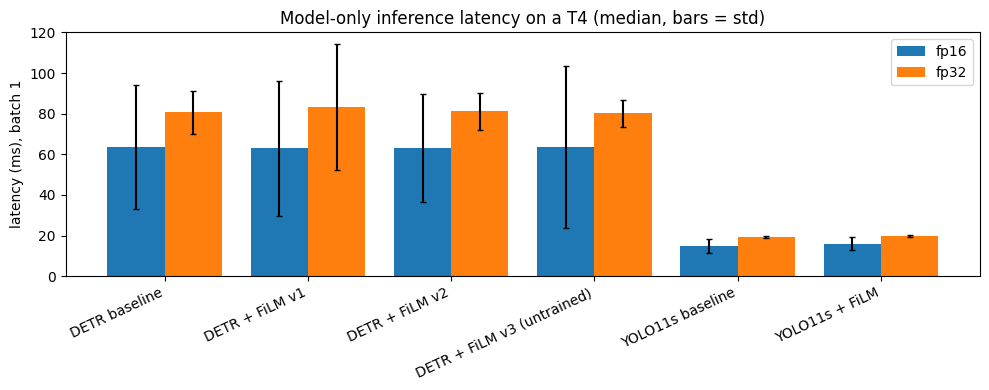

In [ ]:
# ==== Cost profile: params, FLOPs, latency, FPS, memory (random inputs, no dataset needed) ====
if "CLASS_NAMES" not in globals():
    CLASS_NAMES = ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
YOLO_W, YOLO_H = 1280, 640            # YOLO input size used in all experiments
DETR_H, DETR_W = 666, 1333            # what DetrImageProcessor produces for a 2048x1024 image

# ---- settings ----
BATCH_SIZES    = (1,)
PRECISIONS     = ("fp16", "fp32")
ROUNDS, N_WARM, N_ITERS = 3, 20, 100
INCLUDE_V3     = True

CONFIGS = [  # name, builder, family, kind
    ("DETR baseline",              build_detr_baseline,                       "detr", None),
    ("DETR + FiLM v1",             build_detr_film,                           "detr", "v1"),
    ("DETR + FiLM v2",             lambda: build_detr_film_v2(stages=(3, 4)), "detr", "v2"),
    ("DETR + FiLM v3 (untrained)", build_detr_film_v3,                        "detr", "v3"),
    ("YOLO11s baseline",           lambda: build_ultra("yolo11s"),            "yolo", None),
    ("YOLO11s + FiLM",             build_yolo_film,                           "yolo", "yolo"),
]
if not INCLUDE_V3:
    CONFIGS = [c for c in CONFIGS if c[3] != "v3"]
BASELINE_OF = {"DETR + FiLM v1": "DETR baseline", "DETR + FiLM v2": "DETR baseline",
               "DETR + FiLM v3 (untrained)": "DETR baseline", "YOLO11s + FiLM": "YOLO11s baseline"}
B0 = BATCH_SIZES[0]

def gpu_state():
    r = subprocess.run(["nvidia-smi", "--query-gpu=name,clocks.sm,clocks.max.sm,temperature.gpu,power.draw",
                        "--format=csv,noheader"], capture_output=True, text=True)
    return r.stdout.strip()

models = {}
for name, builder, family, kind in CONFIGS:
    models[name] = builder().eval()
    for p in models[name].parameters():
        p.requires_grad_(False)
print("built:", list(models))

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def make_fwd(model, family, kind, B, prec):
    """A zero-argument forward pass on random input of the right shape (beta fixed at 0.5 for FiLM models)."""
    beta = torch.full((B,), 0.5, device=device)
    if family == "detr":
        px = torch.randn(B, 3, DETR_H, DETR_W, device=device)
        pm = torch.ones(B, DETR_H, DETR_W, dtype=torch.long, device=device)
        def call():
            if kind: model.model.backbone.beta = beta
            return model(pixel_values=px, pixel_mask=pm)
    else:
        px = torch.rand(B, 3, YOLO_H, YOLO_W, device=device)
        def call():
            if kind: model.beta = beta
            return model(px)
    if prec == "fp32":
        return call
    def call16():
        with torch.autocast("cuda", dtype=torch.float16):
            return call()
    return call16

@torch.no_grad()
def count_flops(fwd):
    with FlopCounterMode(display=False) as fc:
        fwd()
    return fc.get_total_flops()

@torch.no_grad()
def film_elementwise_gflops(model, family, kind, fwd):
    """FiLM's per-pixel x*(1+g)+d is invisible to the counter; count it from the real feature shapes (2 ops/element)."""
    if not kind:
        return 0.0
    sizes, hooks = [], []
    def rec_out(m, i, o): sizes.append(o.numel() // o.shape[0])
    def rec_in(m, a):
        for t in a[0]: sizes.append(t.numel() // t.shape[0])
    if family == "detr":
        if kind == "v3":
            hooks.append(model.model.input_projection.register_forward_hook(rec_out))
        else:
            for s in ((1, 2, 3, 4) if kind == "v1" else (3, 4)):
                hooks.append(getattr(model.model.backbone.model, f"layer{s}").register_forward_hook(rec_out))
    else:
        hooks.append(model.model[-1].register_forward_pre_hook(rec_in))
    fwd()
    for h in hooks:
        h.remove()
    return 2 * sum(sizes) / 1e9

@torch.no_grad()
def time_once(fwd, n_warm, n_iters):
    for _ in range(n_warm):
        fwd()
    torch.cuda.synchronize()
    ts = []
    for _ in range(n_iters):
        s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        s.record(); fwd(); e.record(); e.synchronize()
        ts.append(s.elapsed_time(e))
    return np.array(ts)

# ---- 1) static cost (batch 1, fp32) ----
static = []
for name, builder, family, kind in CONFIGS:
    m = models[name]
    f1 = make_fwd(m, family, kind, 1, "fp32")
    g = count_flops(f1) / 1e9
    extra = film_elementwise_gflops(m, family, kind, f1)
    static.append(dict(model=name, params_M=n_params(m) / 1e6, film_params=(n_params(m.film) if kind else 0),
                       gflops_counter=g, film_elementwise_gflops=extra, gflops_total=g + extra, gmacs_total=(g + extra) / 2))
static_df = pd.DataFrame(static)
weights_gb = static_df.set_index("model").params_M * 1e6 * 4 / 1e9      # fp32 weights

# ---- 2) latency / memory: all configs resident, timed in interleaved rounds to cancel GPU drift ----
fwds = {(n, B, p): make_fwd(models[n], fam, kind, B, p)
        for n, _, fam, kind in CONFIGS for B in BATCH_SIZES for p in PRECISIONS}
print("GPU before:", gpu_state())
with torch.no_grad():
    for f in fwds.values():
        for _ in range(3): f()
torch.cuda.synchronize()

mem = {}
for key, f in fwds.items():
    torch.cuda.empty_cache(); torch.cuda.synchronize()
    base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad(): f()
    torch.cuda.synchronize()
    mem[key] = (torch.cuda.max_memory_allocated() - base) / 1e9

lat = {k: [] for k in fwds}
for r in range(ROUNDS):
    for key, f in fwds.items():
        lat[key].append(time_once(f, N_WARM, N_ITERS))
    print(f"round {r + 1}/{ROUNDS} done")
print("GPU after: ", gpu_state())

rows = []
for (name, B, prec), runs in lat.items():
    allt, meds = np.concatenate(runs), [np.median(x) for x in runs]
    rows.append(dict(model=name, batch=B, precision=prec, mean_ms=allt.mean(), median_ms=np.median(allt),
                     p95_ms=np.percentile(allt, 95), std_ms=allt.std(), fps=B * 1000 / allt.mean(),
                     round_spread_pct=100 * (max(meds) - min(meds)) / np.median(allt),
                     act_mem_GB=mem[(name, B, prec)]))
timing_df = pd.DataFrame(rows)
timing_df["total_mem_GB"] = timing_df.act_mem_GB + timing_df["model"].map(weights_gb)

# ---- 3) post-processing, timed on synthetic worst-case input (real-image timing belongs in the picture session) ----
@torch.no_grad()
def yolo_postprocess(y, conf_thr=0.001, iou_thr=0.7, max_det=100, pre_nms=3000):   # mirrors decode_yolo
    out = []
    for yi in y.float():
        boxes, scores = yi[:4].T, yi[4:].T
        cx, cy, w, h = boxes.unbind(-1)
        boxes = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)
        a, c = (scores > conf_thr).nonzero(as_tuple=True)
        s = scores[a, c]
        if len(s) > pre_nms:
            top = s.topk(pre_nms).indices; a, c, s = a[top], c[top], s[top]
        b = boxes[a]
        keep = batched_nms(b, s, c, iou_thr)[:max_det]
        out.append((b[keep].cpu(), s[keep].cpu(), c[keep].cpu()))
    return out

@torch.no_grad()
def detr_postprocess(logits, boxes):
    scores, labels = logits.float().softmax(-1)[..., :-1].max(-1)
    cx, cy, w, h = boxes.float().unbind(-1)
    xyxy = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)
    return xyxy.cpu(), scores.cpu(), labels.cpu()

A = 16800                                        # anchors at 1280x640
y_syn = torch.zeros(1, 4 + NUM_CLASSES, A, device=device)
y_syn[0, 0] = torch.rand(A, device=device) * YOLO_W; y_syn[0, 1] = torch.rand(A, device=device) * YOLO_H
y_syn[0, 2:4] = torch.rand(2, A, device=device) * 190 + 10
idx = torch.randperm(A * NUM_CLASSES, device=device)[:6000]      # 6,000 candidates > the 3,000 cap = worst case
y_syn[0, 4:].view(-1)[idx] = torch.rand(6000, device=device) * 0.9 + 0.002
lg, bx = torch.randn(1, 100, NUM_CLASSES + 1, device=device), torch.rand(1, 100, 4, device=device)
post_ms = {"yolo": float(np.median(time_once(lambda: yolo_postprocess(y_syn), 10, 100))),
           "detr": float(np.median(time_once(lambda: detr_postprocess(lg, bx), 10, 100)))}
print(f"post-processing (median ms): DETR {post_ms['detr']:.2f} | YOLO decode+NMS, 3,000-candidate worst case {post_ms['yolo']:.2f}")

# ---- 4) tables ----
t_idx = timing_df.set_index(["model", "batch", "precision"])
s_idx = static_df.set_index("model")
size_rows, speed_rows, over_rows = [], [], []
for name, _, fam, kind in CONFIGS:
    s = s_idx.loc[name]
    size_rows.append(dict(model=name, params_M=s.params_M, film_params=int(s.film_params), GFLOPs_counter=s.gflops_counter,
                          FiLM_elementwise_GFLOPs=s.film_elementwise_gflops, GFLOPs_total=s.gflops_total, GMACs_total=s.gmacs_total))
    r = dict(model=name)
    for prec in PRECISIONS:
        t = t_idx.loc[(name, B0, prec)]
        r.update({f"{prec}_median_ms": t.median_ms, f"{prec}_p95_ms": t.p95_ms, f"{prec}_FPS": t.fps,
                  f"{prec}_noise_pct": t.round_spread_pct, f"{prec}_mem_GB": t.total_mem_GB})
    r["postproc_ms"] = post_ms[fam]
    if "fp16" in PRECISIONS:
        r["e2e_fp16_ms"] = r["fp16_median_ms"] + post_ms[fam]
    speed_rows.append(r)
for film, base in BASELINE_OF.items():
    if film not in s_idx.index or base not in s_idx.index:
        continue
    o = dict(model=film, vs=base,
             d_params_pct=100 * (s_idx.loc[film].params_M / s_idx.loc[base].params_M - 1),
             d_GFLOPs_pct=100 * (s_idx.loc[film].gflops_total / s_idx.loc[base].gflops_total - 1))
    for prec in PRECISIONS:
        a, b = t_idx.loc[(film, B0, prec)], t_idx.loc[(base, B0, prec)]
        o[f"d_latency_{prec}_pct"] = 100 * (a.median_ms / b.median_ms - 1)
        o[f"d_mem_{prec}_pct"] = 100 * (a.total_mem_GB / b.total_mem_GB - 1)
        o[f"noise_{prec}_pct"] = max(a.round_spread_pct, b.round_spread_pct)   # differences below this are not resolved
    over_rows.append(o)
size_df, speed_df, over_df = pd.DataFrame(size_rows), pd.DataFrame(speed_rows), pd.DataFrame(over_rows)

print(f"\nSize and FLOPs (batch 1, input {DETR_H}x{DETR_W} for DETR, {YOLO_H}x{YOLO_W} for YOLO):")
print(size_df.round(4).to_string(index=False))
print(f"\nLatency, FPS and memory (batch {B0}; median ms over {ROUNDS * N_ITERS} passes; noise = spread of round medians):")
print(speed_df.round(2).to_string(index=False))
print("\nFiLM overhead relative to its baseline:")
print(over_df.round(2).to_string(index=False))

size_df.to_csv(f"{RESULTS_DIR}/compute_size_flops.csv", index=False)
speed_df.to_csv(f"{RESULTS_DIR}/compute_speed_memory.csv", index=False)
over_df.to_csv(f"{RESULTS_DIR}/compute_film_overhead.csv", index=False)
timing_df.to_csv(f"{RESULTS_DIR}/compute_timing_all.csv", index=False)

# ---- 5) latency figure ----
names = [c[0] for c in CONFIGS]; x = np.arange(len(names)); wd = 0.8 / len(PRECISIONS)
fig, ax = plt.subplots(figsize=(10, 4))
for j, prec in enumerate(PRECISIONS):
    d = timing_df[(timing_df.batch == B0) & (timing_df.precision == prec)].set_index("model").loc[names]
    ax.bar(x + (j - (len(PRECISIONS) - 1) / 2) * wd, d.median_ms, wd, yerr=d.std_ms, capsize=2, label=prec)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=25, ha="right"); ax.set_ylabel(f"latency (ms), batch {B0}")
ax.set_title("Model-only inference latency on a T4 (median, bars = std)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/compute_latency.png", dpi=200); plt.show()

scenes:
                   scene      city  n  n_cls  n_vru
frankfurt_000001_075984 frankfurt 18      6     11
  munster_000097_000019   munster 27      3     12
single-file download: 6/6 images


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
Overriding model.yaml nc=80 with nc=8
Transferred 493/499 items from pretrained weights
loaded: ['DETR baseline', 'DETR + FiLM v1', 'DETR + FiLM v2', 'YOLO11s baseline', 'YOLO11s + FiLM']


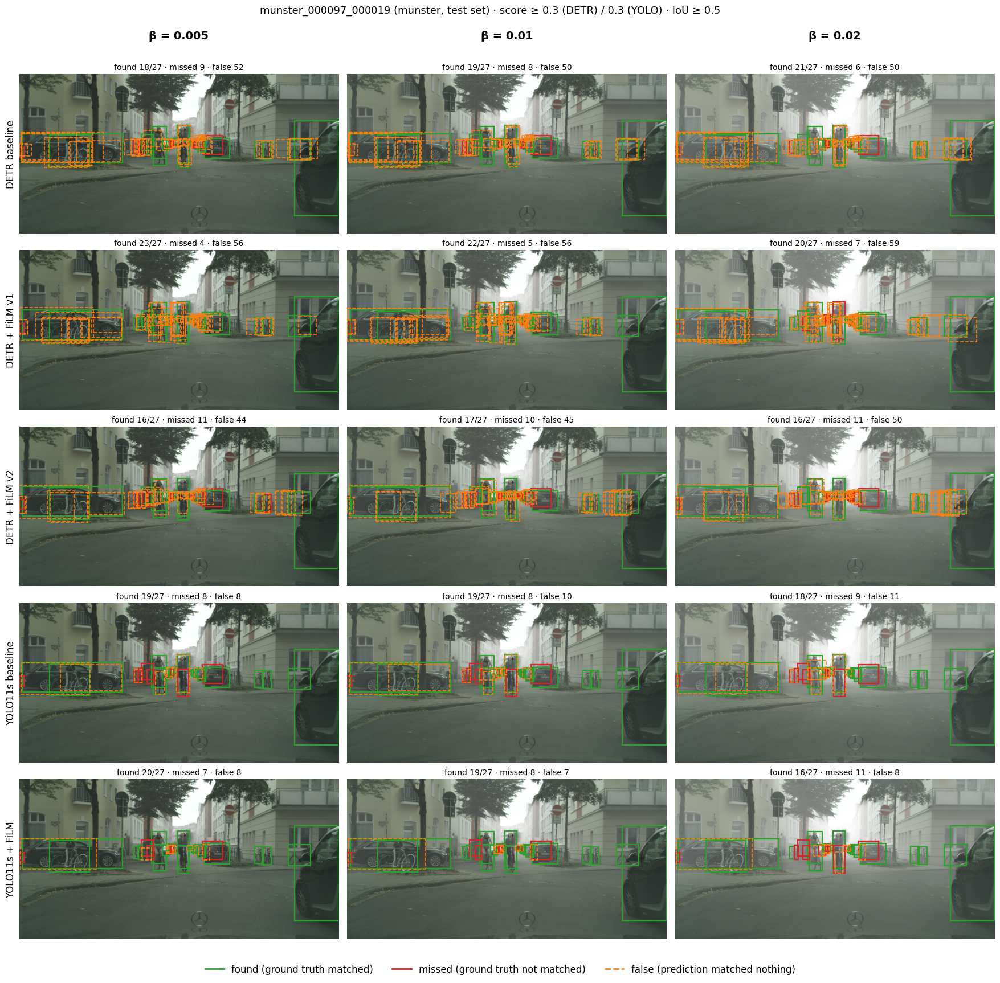

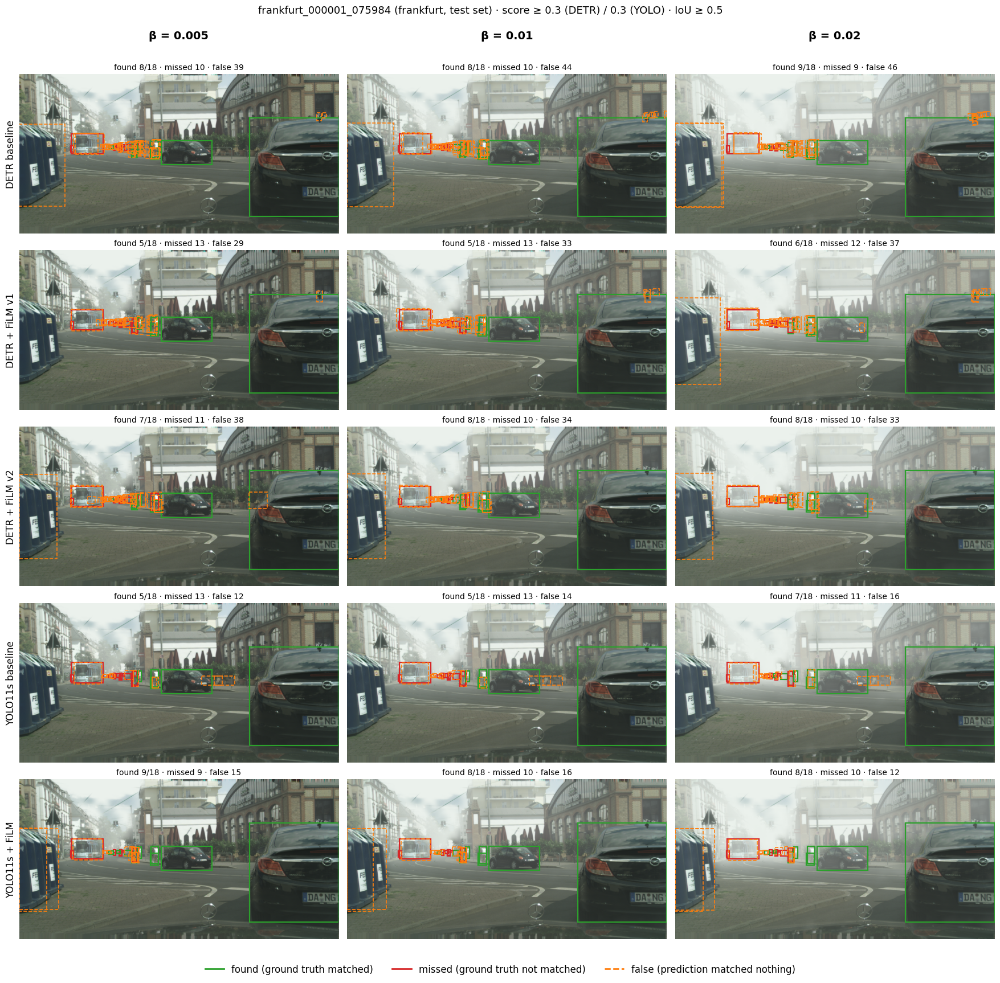

                  scene  beta            model  n_gt  found  missed  false_pos  recall  precision
  munster_000097_000019 0.005    DETR baseline    27     18       9         52   0.667      0.257
  munster_000097_000019 0.005   DETR + FiLM v1    27     23       4         56   0.852      0.291
  munster_000097_000019 0.005   DETR + FiLM v2    27     16      11         44   0.593      0.267
  munster_000097_000019 0.005 YOLO11s baseline    27     19       8          8   0.704      0.704
  munster_000097_000019 0.005   YOLO11s + FiLM    27     20       7          8   0.741      0.714
  munster_000097_000019 0.010    DETR baseline    27     19       8         50   0.704      0.275
  munster_000097_000019 0.010   DETR + FiLM v1    27     22       5         56   0.815      0.282
  munster_000097_000019 0.010   DETR + FiLM v2    27     17      10         45   0.630      0.274
  munster_000097_000019 0.010 YOLO11s baseline    27     19       8         10   0.704      0.655
  munster_000097_000

In [ ]:
# ==== Qualitative figure: found / missed / false detections for each model across beta ====
SCENES    = None
N_SCENES  = 2
SCORE_THR = {"DETR": 0.3, "YOLO": 0.3}
IOU_THR   = 0.5                           # a ground-truth box counts as found at IoU >= 0.5 with the right class
SHOW_FP   = True                          # draw false positives as dashed orange boxes
MODELS = [  # name, family, builder, checkpoint, uses_beta
    ("DETR baseline",    "DETR", build_detr_baseline,                       "detr_baseline", False),
    ("DETR + FiLM v1",   "DETR", build_detr_film,                           "detr_film",     True),
    ("DETR + FiLM v2",   "DETR", lambda: build_detr_film_v2(stages=(3, 4)), "detr_film_v2",  True),
    ("YOLO11s baseline", "YOLO", lambda: build_ultra("yolo11s"),            "yolo_baseline", False),
    ("YOLO11s + FiLM",   "YOLO", build_yolo_film,                           "yolo_film",     True),
]
if "CLASS_NAMES" not in globals():
    CLASS_NAMES = ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
YOLO_W, YOLO_H = 1280, 640
RAW_DIR = "/content/raw"
BETA_NORM_IMG = {0.005: 0.0, 0.01: 0.5, 0.02: 1.0}

idx = pd.read_csv(f"{RESULTS_DIR}/data_index.csv")
with open(f"{RESULTS_DIR}/boxes.pkl", "rb") as f:
    BOXES = pickle.load(f)
test = idx[idx.role == "test"].copy()
sc = test.drop_duplicates("scene").copy()
st = pd.DataFrame([(len(BOXES[p]), len(set(BOXES[p][:, 4].astype(int).tolist())), int(np.isin(BOXES[p][:, 4].astype(int), [0, 1, 6, 7]).sum()))
                   for p in sc.ann_path], columns=["n", "n_cls", "n_vru"], index=sc.index)
sc = sc.join(st)
if SCENES is None:
    elig = sc[sc.n.between(12, 30) & (sc.n_cls >= 3) & (sc.n_vru >= 3)].sample(frac=1, random_state=SEED)
    SCENES, used = [], set()
    for r in elig.itertuples():
        if r.city not in used:
            SCENES.append(r.scene); used.add(r.city)
        if len(SCENES) == N_SCENES: break
    for r in elig.itertuples():
        if len(SCENES) >= N_SCENES: break
        if r.scene not in SCENES: SCENES.append(r.scene)
print("scenes:\n", sc[sc.scene.isin(SCENES)][["scene", "city", "n", "n_cls", "n_vru"]].to_string(index=False))
need = test[test.scene.isin(SCENES)].sort_values(["scene", "beta"])
assert len(need) == 3 * len(SCENES), "each scene must have all 3 betas"

def fetch_images(paths):
    rels = [os.path.relpath(p, FOGGY_DIR) for p in paths]
    todo = [r for r in rels if not os.path.exists(f"{FOGGY_DIR}/{r}")]
    if not todo:
        print("images already on disk"); return
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    for r in todo:
        dest = f"{FOGGY_DIR}/{os.path.dirname(r)}"; target = f"{FOGGY_DIR}/{r}"; base = os.path.basename(r)
        os.makedirs(dest, exist_ok=True)
        subprocess.run(["kaggle", "datasets", "download", "-d", "minhducnguyen9705/foggy-cityscapes",
                        "-f", r, "-p", dest, "-q"], capture_output=True, text=True)
        for z in glob.glob(f"{dest}/**/{base}.zip", recursive=True):
            with zipfile.ZipFile(z) as zf: zf.extractall(dest)
            os.remove(z)
        hits = glob.glob(f"{dest}/**/{base}", recursive=True)
        if hits and hits[0] != target:
            shutil.move(hits[0], target)
    todo = [r for r in rels if not os.path.exists(f"{FOGGY_DIR}/{r}")]
    print(f"single-file download: {len(rels) - len(todo)}/{len(rels)} images")
    if todo:
        os.makedirs(RAW_DIR, exist_ok=True)
        subprocess.run(["kaggle", "datasets", "download", "-d", "minhducnguyen9705/foggy-cityscapes", "-p", RAW_DIR, "-q"])
        zpath = f"{RAW_DIR}/foggy-cityscapes.zip"
        with zipfile.ZipFile(zpath) as zf:
            for r in todo: zf.extract(r, FOGGY_DIR)
        os.remove(zpath)
    assert all(os.path.exists(f"{FOGGY_DIR}/{r}") for r in rels), "some images are still missing"
fetch_images(need.img_path.tolist())

# ---- load the five trained models (best-dev-loss checkpoints, the same ones evaluated on the test set) ----
det_proc = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50", size={"shortest_edge": 800, "longest_edge": 1333})
nets = {}
for name, fam, builder, ck, ub in MODELS:
    m = builder().eval()
    m.load_state_dict(torch.load(f"{CKPT_DIR}/{ck}_best.pt", map_location=device))
    nets[name] = m
print("loaded:", list(nets))

# ---- predictions ----
@torch.no_grad()
def predict(name, fam, uses_beta, img, beta):
    m, thr = nets[name], SCORE_THR[fam]
    bn = torch.tensor([BETA_NORM_IMG[beta]], device=device)
    W, H = img.size
    if fam == "DETR":
        enc = det_proc(images=img, return_tensors="pt")
        if uses_beta: m.model.backbone.beta = bn
        with torch.autocast("cuda", dtype=torch.float16):
            out = m(pixel_values=enc["pixel_values"].to(device), pixel_mask=enc["pixel_mask"].to(device))
        s, l = out.logits.float().softmax(-1)[0, :, :-1].max(-1)
        cx, cy, w, h = out.pred_boxes.float()[0].unbind(-1)
        b = torch.stack([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H], -1)
        k = s > thr
        return b[k].cpu().numpy(), s[k].cpu().numpy(), l[k].cpu().numpy()
    x = torch.from_numpy(np.asarray(img.resize((YOLO_W, YOLO_H), Image.BILINEAR)).copy()).permute(2, 0, 1)[None].float().div(255).to(device)
    if uses_beta: m.beta = bn
    with torch.autocast("cuda", dtype=torch.float16):
        y = m(x)[0].float()[0]
    boxes, scores = y[:4].T, y[4:].T
    cx, cy, w, h = boxes.unbind(-1)
    boxes = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)
    a, c = (scores > thr).nonzero(as_tuple=True)
    s, b = scores[a, c], boxes[a]
    k = batched_nms(b, s, c, 0.7)[:100]
    b = b[k] * torch.tensor([W / YOLO_W, H / YOLO_H] * 2, device=device)
    return b.cpu().numpy(), s[k].cpu().numpy(), c[k].cpu().numpy()

# ---- matching: found / missed / false ----
def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def match(gt, pb, ps, pl):
    """gt [N,5]=(x1,y1,x2,y2,cls). Greedy by score: a prediction finds an unmatched GT of the same class with IoU >= IOU_THR.
    Returns found[N] (green), missed = ~found (red), false[P] = predictions that matched nothing (orange)."""
    found, used = np.zeros(len(gt), bool), np.zeros(len(pb), bool)
    if len(gt) and len(pb):
        ious = iou_matrix(pb, gt[:, :4])
        for i in np.argsort(-ps):
            cand = np.where((~found) & (gt[:, 4].astype(int) == int(pl[i])) & (ious[i] >= IOU_THR))[0]
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]
                found[j], used[i] = True, True
    return found, ~used

# ---- one figure per scene (rows = models, columns = beta) ----
GREEN, RED, ORANGE = "#2ca02c", "#d62728", "#ff7f0e"
rows = []
for scene in SCENES:
    sr = need[need.scene == scene]
    fig, axes = plt.subplots(len(MODELS), 3, figsize=(18, 3.5 * len(MODELS)))
    for c, beta in enumerate(sorted(sr.beta.unique())):
        row = sr[sr.beta == beta].iloc[0]
        img = Image.open(row.img_path).convert("RGB"); gt = BOXES[row.ann_path]
        for r, (name, fam, _, _, ub) in enumerate(MODELS):
            pb, ps, pl = predict(name, fam, ub, img, beta)
            found, fp = match(gt, pb, ps, pl)
            ax = axes[r, c]; ax.imshow(img); ax.axis("off")
            for (x1, y1, x2, y2, k), ok in zip(gt, found):
                ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.6, edgecolor=GREEN if ok else RED))
            if SHOW_FP:
                for x1, y1, x2, y2 in pb[fp]:
                    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.2, ls="--", edgecolor=ORANGE))
            ax.set_title(f"found {found.sum()}/{len(gt)} · missed {(~found).sum()} · false {fp.sum()}", fontsize=10)
            if c == 0:
                ax.text(-0.01, 0.5, name, transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=12)
            if r == 0:
                ax.text(0.5, 1.22, f"β = {beta}", transform=ax.transAxes, ha="center", fontsize=14, weight="bold")
            rows.append(dict(scene=scene, beta=beta, model=name, n_gt=len(gt), found=int(found.sum()),
                             missed=int((~found).sum()), false_pos=int(fp.sum()),
                             recall=found.sum() / max(len(gt), 1), precision=found.sum() / max(found.sum() + fp.sum(), 1)))
    handles = [plt.Line2D([0], [0], color=GREEN, lw=2), plt.Line2D([0], [0], color=RED, lw=2),
               plt.Line2D([0], [0], color=ORANGE, lw=2, ls="--")]
    fig.legend(handles, ["found (ground truth matched)", "missed (ground truth not matched)", "false (prediction matched nothing)"],
               loc="lower center", ncol=3, fontsize=12, frameon=False)
    fig.suptitle(f"{scene} ({sr.city.iloc[0]}, test set) · score ≥ {SCORE_THR['DETR']} (DETR) / {SCORE_THR['YOLO']} (YOLO) · IoU ≥ {IOU_THR}", fontsize=13)
    plt.tight_layout(rect=(0.02, 0.03, 1, 0.97), h_pad=1.5)
    fig.savefig(f"{RESULTS_DIR}/qual_{scene}.png", dpi=150, bbox_inches="tight")
    plt.show()

counts = pd.DataFrame(rows)
counts.to_csv(f"{RESULTS_DIR}/qual_counts.csv", index=False)
print(counts.round(3).to_string(index=False))

- DETR over-predicts.
  - It produces 29 to 59 false boxes per image against 7 to 16 for YOLO.
  - Precision is 0.13 to 0.30 for DETR and 0.26 to 0.73 for YOLO.
  - At this threshold DETR finds about as many objects as YOLO or more (Frankfurt: 8 of 18 against 5 of 18).
  - Many orange boxes are stacked on the same object. That fits an undertrained DETR producing duplicates, but I haven’t checked the classes.
- Every model misses the small objects near the vanishing point (the red clusters), consistent with the very low AP small.
- All the models behave the same. The baselines and FiLM variants show the same misses and the same false boxes, which matches the null swapped-β result.
- There’s a shared false positive on the blue waste bins in the Frankfurt scene (four of the five models).